# DATASET LOADING

In [1]:

# ============================================================
# STEP 1: DATASET COLLECTION AND INITIAL INSPECTION
# ============================================================

import os
import pandas as pd
import numpy as np

# Dataset path
dataset_path = r"D:\Implementation\4_Health Risk Classification\Dataset\college_student_iot_mental_health_dataset.csv"

# ------------------------------------------------------------
# 1. Check dataset availability
# ------------------------------------------------------------

print("=" * 85)
print("STEP 1: DATASET COLLECTION AND INSPECTION")
print("=" * 85)

if not os.path.exists(dataset_path):
    raise FileNotFoundError(f"Dataset not found: {dataset_path}")

print("\n[1] DATASET FILE INFORMATION")
print("-" * 85)
print("Dataset Name :", os.path.basename(dataset_path))
print("File Size    :", round(os.path.getsize(dataset_path) / (1024 * 1024), 2), "MB")
print("File Path    :", dataset_path)

# ------------------------------------------------------------
# 2. Load dataset
# ------------------------------------------------------------

df = pd.read_csv(dataset_path)

print("\n[2] DATASET LOADING")
print("-" * 85)
print("Dataset loaded successfully!")

# ------------------------------------------------------------
# 3. Dataset dimensions
# ------------------------------------------------------------

print("\n[3] DATASET DIMENSIONS")
print("-" * 85)
print("Total Records :", df.shape[0])
print("Total Columns :", df.shape[1])
print("Dataset Shape :", df.shape)

# ------------------------------------------------------------
# 4. Display column names
# ------------------------------------------------------------

print("\n[4] DATASET ATTRIBUTES")
print("-" * 85)

for index, column in enumerate(df.columns, start=1):
    print(f"{index:02d}. {column}")

# ------------------------------------------------------------
# 5. Data types
# ------------------------------------------------------------

print("\n[5] ATTRIBUTE DATA TYPES")
print("-" * 85)
print(df.dtypes.to_string())

# ------------------------------------------------------------
# 6. Missing values
# ------------------------------------------------------------

print("\n[6] MISSING VALUE INSPECTION")
print("-" * 85)

missing_values = df.isnull().sum()

missing_report = pd.DataFrame({
    "Column": df.columns,
    "Missing_Count": missing_values.values,
    "Missing_Percentage": (
        missing_values.values / len(df) * 100
    ).round(2)
})

print(missing_report.to_string(index=False))

print("\nTotal Missing Values:", df.isnull().sum().sum())

# ------------------------------------------------------------
# 7. Duplicate records
# ------------------------------------------------------------

print("\n[7] DUPLICATE RECORD INSPECTION")
print("-" * 85)

duplicate_count = df.duplicated().sum()

print("Duplicate Records :", duplicate_count)
print("Unique Records    :", len(df) - duplicate_count)

# ------------------------------------------------------------
# 8. Target class distribution
# ------------------------------------------------------------

target_column = "mental_health_risk"

print("\n[8] TARGET CLASS DISTRIBUTION")
print("-" * 85)

if target_column in df.columns:

    class_counts = df[target_column].value_counts(dropna=False)

    class_distribution = pd.DataFrame({
        "Mental Health Risk": class_counts.index,
        "Record Count": class_counts.values,
        "Percentage": (
            class_counts.values / len(df) * 100
        ).round(2)
    })

    print(class_distribution.to_string(index=False))

else:
    print(f"Target column '{target_column}' not found.")
    print("Available columns:", df.columns.tolist())

# ------------------------------------------------------------
# 9. Statistical information
# ------------------------------------------------------------

print("\n[9] NUMERICAL ATTRIBUTE SUMMARY")
print("-" * 85)
print(df.describe().round(3))

# ------------------------------------------------------------
# 10. Display sample records
# ------------------------------------------------------------

print("\n[10] FIRST FIVE DATASET RECORDS")
print("-" * 85)
print(df.head())

# ------------------------------------------------------------
# 11. Final dataset collection summary
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("STEP 1: DATASET COLLECTION COMPLETED")
print("=" * 85)

print("Dataset Shape          :", df.shape)
print("Total Records          :", len(df))
print("Total Attributes       :", len(df.columns))
print("Missing Values         :", df.isnull().sum().sum())
print("Duplicate Records      :", duplicate_count)

if target_column in df.columns:
    print("Target Column          :", target_column)
    print("Number of Target Classes:", df[target_column].nunique())

print("=" * 85)


STEP 1: DATASET COLLECTION AND INSPECTION

[1] DATASET FILE INFORMATION
-------------------------------------------------------------------------------------
Dataset Name : college_student_iot_mental_health_dataset.csv
File Size    : 3.4 MB
File Path    : D:\Implementation\4_Health Risk Classification\Dataset\college_student_iot_mental_health_dataset.csv

[2] DATASET LOADING
-------------------------------------------------------------------------------------
Dataset loaded successfully!

[3] DATASET DIMENSIONS
-------------------------------------------------------------------------------------
Total Records : 15000
Total Columns : 41
Dataset Shape : (15000, 41)

[4] DATASET ATTRIBUTES
-------------------------------------------------------------------------------------
01. student_id
02. session_id
03. age
04. gender
05. year_of_study
06. department
07. residence_type
08. sleep_duration_hr
09. sleep_quality_score
10. heart_rate_bpm
11. resting_heart_rate
12. heart_rate_variability
13

# PREPROCESSING

In [5]:

# ================================================================
# STEP 2: DATA PREPROCESSING
# KNN IMPUTATION + MEDIAN FILTERING + MIN-MAX NORMALIZATION
# ================================================================

import os
import numpy as np
import pandas as pd

from sklearn.impute import KNNImputer
from sklearn.preprocessing import MinMaxScaler
from scipy.ndimage import median_filter

# ------------------------------------------------
# 1. Dataset paths
# ------------------------------------------------

input_path = r"D:\Implementation\4_Health Risk Classification\Dataset\college_student_iot_mental_health_dataset.csv"

output_path = r"D:\Implementation\4_Health Risk Classification\Output\preprocessed_mental_health_dataset.csv"

# ------------------------------------------------
# 2. Load dataset
# ------------------------------------------------

print("=" * 90)
print("STEP 2: DATA PREPROCESSING")
print("=" * 90)

df = pd.read_csv(input_path)

print("\n[1] ORIGINAL DATASET")
print("-" * 90)
print("Dataset Shape:", df.shape)

# ------------------------------------------------
# 3. Identify columns
# ------------------------------------------------

target_column = "mental_health_risk"

identifier_columns = [
    "student_id",
    "session_id"
]

# Numerical predictor columns
numerical_columns = df.select_dtypes(
    include=[np.number]
).columns.tolist()

numerical_features = [
    col for col in numerical_columns
    if col not in identifier_columns
]

print("\n[2] FEATURE IDENTIFICATION")
print("-" * 90)

print("Identifier Columns:", identifier_columns)
print("Numerical Features:", len(numerical_features))
print("Target Column:", target_column)

# ------------------------------------------------
# 4. KNN Imputation
# ------------------------------------------------

print("\n[3] KNN IMPUTATION")
print("-" * 90)

print("Missing Values Before:",
      df[numerical_features].isnull().sum().sum())

knn_imputer = KNNImputer(n_neighbors=5)

df[numerical_features] = knn_imputer.fit_transform(
    df[numerical_features]
)

print("Missing Values After:",
      df[numerical_features].isnull().sum().sum())

print("KNN Imputation Completed Successfully.")

# ------------------------------------------------
# 5. Median Filtering
# ------------------------------------------------

print("\n[4] MEDIAN FILTERING")
print("-" * 90)

# Kernel size for median filtering
filter_size = 3

# Apply median filtering to numerical features
# Excludes identifiers and target column

for col in numerical_features:

    df[col] = median_filter(
        df[col].to_numpy(dtype=np.float64),
        size=filter_size,
        mode="nearest"
    )

print("Median Filter Size:", filter_size)
print("Median Filtering Completed Successfully.")

# ------------------------------------------------
# 6. Min-Max Normalization
# ------------------------------------------------

print("\n[5] MIN-MAX NORMALIZATION")
print("-" * 90)

scaler = MinMaxScaler(feature_range=(0, 1))

df[numerical_features] = scaler.fit_transform(
    df[numerical_features]
)

print("Normalization Range: [0, 1]")
print("Min-Max Normalization Completed Successfully.")

# ------------------------------------------------
# 7. Preserve target and identifiers
# ------------------------------------------------

print("\n[6] TARGET AND IDENTIFIER PRESERVATION")
print("-" * 90)

# Ensure target remains categorical
df[target_column] = df[target_column].astype(str)

# Place target column at the end
columns = [
    col for col in df.columns
    if col != target_column
]

df = df[columns + [target_column]]

print("Target Column:", target_column)
print("Target Data Type:", df[target_column].dtype)

# ------------------------------------------------
# 8. Verify preprocessing
# ------------------------------------------------

print("\n[7] PREPROCESSING VERIFICATION")
print("-" * 90)

print("Dataset Shape:", df.shape)
print("Remaining Missing Values:", df.isnull().sum().sum())

print("\nNumerical Feature Range:")

print(
    df[numerical_features]
    .agg(["min", "max"])
    .round(4)
)

print("\nTarget Class Distribution:")

print(
    df[target_column]
    .value_counts()
)

# ------------------------------------------------
# 9. Save preprocessed dataset
# ------------------------------------------------

os.makedirs(os.path.dirname(output_path), exist_ok=True)

df.to_csv(output_path, index=False)

print("\n[8] SAVING PREPROCESSED DATASET")
print("-" * 90)

print("Preprocessed Dataset Saved Successfully!")
print("Output File:", output_path)
print("Final Dataset Shape:", df.shape)
print(df.head())


STEP 2: DATA PREPROCESSING

[1] ORIGINAL DATASET
------------------------------------------------------------------------------------------
Dataset Shape: (15000, 41)

[2] FEATURE IDENTIFICATION
------------------------------------------------------------------------------------------
Identifier Columns: ['student_id', 'session_id']
Numerical Features: 34
Target Column: mental_health_risk

[3] KNN IMPUTATION
------------------------------------------------------------------------------------------
Missing Values Before: 0
Missing Values After: 0
KNN Imputation Completed Successfully.

[4] MEDIAN FILTERING
------------------------------------------------------------------------------------------
Median Filter Size: 3
Median Filtering Completed Successfully.

[5] MIN-MAX NORMALIZATION
------------------------------------------------------------------------------------------
Normalization Range: [0, 1]
Min-Max Normalization Completed Successfully.

[6] TARGET AND IDENTIFIER PRESERVATION
-

# SPLITTING

In [6]:

# ================================================================
# STEP 3: STRATIFIED TRAIN-TEST SPLITTING (70:30)
# ================================================================

import os
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

# ------------------------------------------------
# 1. Dataset paths
# ------------------------------------------------

input_path = r"D:\Implementation\4_Health Risk Classification\Output\preprocessed_mental_health_dataset.csv"

output_dir = r"D:\Implementation\4_Health Risk Classification\Output"

train_path = os.path.join(
    output_dir, "mental_health_training_dataset.csv"
)

test_path = os.path.join(
    output_dir, "mental_health_testing_dataset.csv"
)

# ------------------------------------------------
# 2. Load preprocessed dataset
# ------------------------------------------------

print("=" * 90)
print("STEP 3: STRATIFIED TRAIN-TEST SPLITTING")
print("=" * 90)

df = pd.read_csv(input_path)

print("\n[1] PREPROCESSED DATASET")
print("-" * 90)

print("Dataset Shape:", df.shape)
print("Total Records:", len(df))

# ------------------------------------------------
# 3. Define target and features
# ------------------------------------------------

target_column = "mental_health_risk"

identifier_columns = [
    "student_id",
    "session_id"
]

if target_column not in df.columns:
    raise ValueError("Target column not found!")

# Exclude identifiers and target from model features
feature_columns = [
    col for col in df.columns
    if col not in identifier_columns + [target_column]
]

X = df[feature_columns]
y = df[target_column]

print("\n[2] FEATURE AND TARGET SEPARATION")
print("-" * 90)

print("Total Model Input Features:", len(feature_columns))
print("Identifier Columns:", identifier_columns)
print("Target Column:", target_column)
print("Target Classes:", sorted(y.unique()))

# ------------------------------------------------
# 4. Original class distribution
# ------------------------------------------------

print("\n[3] ORIGINAL CLASS DISTRIBUTION")
print("-" * 90)

original_distribution = pd.DataFrame({
    "Class": y.value_counts().index,
    "Records": y.value_counts().values,
    "Percentage": (
        y.value_counts(normalize=True).values * 100
    ).round(2)
})

print(original_distribution.to_string(index=False))

# ------------------------------------------------
# 5. Stratified train-test splitting
# ------------------------------------------------

print("\n[4] STRATIFIED TRAIN-TEST SPLITTING")
print("-" * 90)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Training Records:", len(X_train))
print("Testing Records :", len(X_test))
print("Training Ratio  : 70%")
print("Testing Ratio   : 30%")
print("Random State    : 42")
print("Stratification  : Enabled")

# ------------------------------------------------
# 6. Reconstruct training and testing datasets
# ------------------------------------------------

train_df = df.loc[X_train.index].copy()
test_df = df.loc[X_test.index].copy()

# ------------------------------------------------
# 7. Verify class distribution
# ------------------------------------------------

print("\n[5] TRAINING CLASS DISTRIBUTION")
print("-" * 90)

train_distribution = pd.DataFrame({
    "Class": y_train.value_counts().index,
    "Records": y_train.value_counts().values,
    "Percentage": (
        y_train.value_counts(normalize=True).values * 100
    ).round(2)
})

print(train_distribution.to_string(index=False))

print("\n[6] TESTING CLASS DISTRIBUTION")
print("-" * 90)

test_distribution = pd.DataFrame({
    "Class": y_test.value_counts().index,
    "Records": y_test.value_counts().values,
    "Percentage": (
        y_test.value_counts(normalize=True).values * 100
    ).round(2)
})

print(test_distribution.to_string(index=False))

# ------------------------------------------------
# 8. Verify dataset dimensions
# ------------------------------------------------

print("\n[7] SPLIT DATASET DIMENSIONS")
print("-" * 90)

print("Training Dataset Shape:", train_df.shape)
print("Testing Dataset Shape :", test_df.shape)

print("Training Features Shape:", X_train.shape)
print("Testing Features Shape :", X_test.shape)

print("Training Target Shape:", y_train.shape)
print("Testing Target Shape :", y_test.shape)

# ------------------------------------------------
# 9. Verify class representation
# ------------------------------------------------

print("\n[8] STRATIFICATION VERIFICATION")
print("-" * 90)

for class_name in sorted(y.unique()):

    original_pct = (y == class_name).mean() * 100
    train_pct = (y_train == class_name).mean() * 100
    test_pct = (y_test == class_name).mean() * 100

    print(
        f"{class_name:<12} "
        f"Original: {original_pct:6.2f}% | "
        f"Training: {train_pct:6.2f}% | "
        f"Testing: {test_pct:6.2f}%"
    )

# ------------------------------------------------
# 10. Save training and testing datasets
# ------------------------------------------------

os.makedirs(output_dir, exist_ok=True)

train_df.to_csv(train_path, index=False)
test_df.to_csv(test_path, index=False)

print("\n[9] SAVING SPLIT DATASETS")
print("-" * 90)

print("Training Dataset Saved:")
print(train_path)

print("\nTesting Dataset Saved:")
print(test_path)

# ------------------------------------------------
# 11. Final summary
# ------------------------------------------------

print("\n" + "=" * 90)
print("STEP 3: TRAIN-TEST SPLITTING COMPLETED")
print("=" * 90)

print("Original Records      :", len(df))
print("Training Records      :", len(train_df))
print("Testing Records       :", len(test_df))
print("Training Percentage  : 70%")
print("Testing Percentage   : 30%")
print("Training Features     :", len(feature_columns))
print("Target Classes        :", y.nunique())
print("Stratified Split      : Successful")

print("\nTraining File:", train_path)
print("Testing File :", test_path)

print("=" * 90)


STEP 3: STRATIFIED TRAIN-TEST SPLITTING

[1] PREPROCESSED DATASET
------------------------------------------------------------------------------------------
Dataset Shape: (15000, 41)
Total Records: 15000

[2] FEATURE AND TARGET SEPARATION
------------------------------------------------------------------------------------------
Total Model Input Features: 38
Identifier Columns: ['student_id', 'session_id']
Target Column: mental_health_risk
Target Classes: ['Critical', 'High', 'Low', 'Moderate']

[3] ORIGINAL CLASS DISTRIBUTION
------------------------------------------------------------------------------------------
   Class  Records  Percentage
Critical     8208       54.72
    High     4714       31.43
Moderate     1808       12.05
     Low      270        1.80

[4] STRATIFIED TRAIN-TEST SPLITTING
------------------------------------------------------------------------------------------
Training Records: 10500
Testing Records : 4500
Training Ratio  : 70%
Testing Ratio   : 30%
Random

# FEATURE EXTRACTION

In [7]:

# ================================================================
# STEP 4: PRINCIPAL COMPONENT ANALYSIS (PCA)
# DIMENSIONALITY REDUCTION: 38 INPUT ATTRIBUTES -> 20 COMPONENTS
# ================================================================

import os
import joblib
import numpy as np
import pandas as pd

from sklearn.decomposition import PCA
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

# ------------------------------------------------
# 1. Define dataset paths
# ------------------------------------------------

output_dir = r"D:\Implementation\4_Health Risk Classification\Output"

train_path = os.path.join(
    output_dir, "mental_health_training_dataset.csv"
)

test_path = os.path.join(
    output_dir, "mental_health_testing_dataset.csv"
)

pca_train_path = os.path.join(
    output_dir, "pca_training_dataset.csv"
)

pca_test_path = os.path.join(
    output_dir, "pca_testing_dataset.csv"
)

encoder_path = os.path.join(
    output_dir, "pca_encoder.pkl"
)

pca_model_path = os.path.join(
    output_dir, "pca_model.pkl"
)

# ------------------------------------------------
# 2. Load training and testing datasets
# ------------------------------------------------

print("=" * 90)
print("STEP 4: PRINCIPAL COMPONENT ANALYSIS (PCA)")
print("=" * 90)

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

print("\n[1] DATASET LOADING")
print("-" * 90)

print("Training Dataset Shape:", train_df.shape)
print("Testing Dataset Shape :", test_df.shape)

# ------------------------------------------------
# 3. Separate features and target
# ------------------------------------------------

target_column = "mental_health_risk"

identifier_columns = [
    "student_id",
    "session_id"
]

excluded_columns = identifier_columns + [target_column]

feature_columns = [
    col for col in train_df.columns
    if col not in excluded_columns
]

X_train = train_df[feature_columns].copy()
X_test = test_df[feature_columns].copy()

y_train = train_df[target_column].copy()
y_test = test_df[target_column].copy()

print("\n[2] FEATURE AND TARGET SEPARATION")
print("-" * 90)

print("Original Input Features:", len(feature_columns))
print("Training Samples:", len(X_train))
print("Testing Samples :", len(X_test))
print("Target Column:", target_column)

# ------------------------------------------------
# 4. Identify numerical and categorical features
# ------------------------------------------------

numerical_columns = X_train.select_dtypes(
    include=[np.number]
).columns.tolist()

categorical_columns = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("\n[3] FEATURE TYPE IDENTIFICATION")
print("-" * 90)

print("Numerical Features:", len(numerical_columns))
print("Categorical Features:", len(categorical_columns))

print("Numerical Columns:", numerical_columns)
print("Categorical Columns:", categorical_columns)

# ------------------------------------------------
# 5. Encode categorical attributes
# ------------------------------------------------

print("\n[4] CATEGORICAL ATTRIBUTE ENCODING")
print("-" * 90)

# One-hot encoder with compatibility for sklearn versions

try:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )
except TypeError:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )

transformers = []

if len(numerical_columns) > 0:
    transformers.append(
        ("numerical", "passthrough", numerical_columns)
    )

if len(categorical_columns) > 0:
    transformers.append(
        ("categorical", encoder, categorical_columns)
    )

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop",
    verbose_feature_names_out=False
)

# Fit only on training data
X_train_encoded = preprocessor.fit_transform(X_train)

# Apply the same encoder to testing data
X_test_encoded = preprocessor.transform(X_test)

X_train_encoded = np.asarray(X_train_encoded, dtype=np.float64)
X_test_encoded = np.asarray(X_test_encoded, dtype=np.float64)

print("Training Encoded Shape:", X_train_encoded.shape)
print("Testing Encoded Shape :", X_test_encoded.shape)

print("Categorical Encoding Completed.")

# ------------------------------------------------
# 6. Apply PCA
# ------------------------------------------------

print("\n[5] PRINCIPAL COMPONENT ANALYSIS")
print("-" * 90)

n_components = 20

if X_train_encoded.shape[1] < n_components:
    raise ValueError(
        "Number of encoded features is less than 20."
    )

pca = PCA(
    n_components=n_components,
    random_state=42
)

# Fit PCA on training data only
X_train_pca = pca.fit_transform(X_train_encoded)

# Transform testing data using the fitted PCA
X_test_pca = pca.transform(X_test_encoded)

print("Original Encoded Features:", X_train_encoded.shape[1])
print("Selected PCA Components:", n_components)

print("Training PCA Shape:", X_train_pca.shape)
print("Testing PCA Shape :", X_test_pca.shape)

# ------------------------------------------------
# 7. Calculate explained variance
# ------------------------------------------------

print("\n[6] EXPLAINED VARIANCE ANALYSIS")
print("-" * 90)

explained_variance = pca.explained_variance_ratio_

cumulative_variance = np.cumsum(
    explained_variance
)

variance_table = pd.DataFrame({
    "Component": [
        f"PC{i+1}" for i in range(n_components)
    ],
    "Explained_Variance_Percentage":
        explained_variance * 100,
    "Cumulative_Variance_Percentage":
        cumulative_variance * 100
})

print(variance_table.round(4))

print("\nTotal Explained Variance: "
      f"{cumulative_variance[-1] * 100:.2f}%")

# ------------------------------------------------
# 8. Construct PCA datasets
# ------------------------------------------------

print("\n[7] CONSTRUCTING PCA DATASETS")
print("-" * 90)

pca_columns = [
    f"PC{i+1}" for i in range(n_components)
]

pca_train_df = pd.DataFrame(
    X_train_pca,
    columns=pca_columns,
    index=train_df.index
)

pca_test_df = pd.DataFrame(
    X_test_pca,
    columns=pca_columns,
    index=test_df.index
)

# Preserve identifiers and target
for col in identifier_columns:
    pca_train_df.insert(
        0, col, train_df[col].values
    )

    pca_test_df.insert(
        0, col, test_df[col].values
    )

pca_train_df[target_column] = y_train.values
pca_test_df[target_column] = y_test.values

print("Training PCA Dataset:", pca_train_df.shape)
print("Testing PCA Dataset :", pca_test_df.shape)

# ------------------------------------------------
# 9. Save PCA datasets
# ------------------------------------------------

print("\n[8] SAVING PCA DATASETS")
print("-" * 90)

pca_train_df.to_csv(
    pca_train_path,
    index=False
)

pca_test_df.to_csv(
    pca_test_path,
    index=False
)

joblib.dump(preprocessor, encoder_path)
joblib.dump(pca, pca_model_path)

print("Training PCA Dataset Saved:")
print(pca_train_path)

print("\nTesting PCA Dataset Saved:")
print(pca_test_path)

# ------------------------------------------------
# 10. Final verification
# ------------------------------------------------

print("\n[9] FINAL PCA VERIFICATION")
print("-" * 90)

print("Training Dataset Shape:", pca_train_df.shape)
print("Testing Dataset Shape :", pca_test_df.shape)

print("Training PCA Features:", len(pca_columns))
print("Testing PCA Features :", len(pca_columns))
print("Training Sample:", pca_train_df.head())
print("Testing Sample :", pca_test_df.head())
print("Training Missing Values:",
      pca_train_df.isnull().sum().sum())

print("Testing Missing Values:",
      pca_test_df.isnull().sum().sum())

print("Training Target Classes:",
      pca_train_df[target_column].nunique())

print("Testing Target Classes:",
      pca_test_df[target_column].nunique())

print("\n" + "=" * 90)
print("STEP 4: PCA DIMENSIONALITY REDUCTION COMPLETED")
print("=" * 90)

print("PCA Training File       :", pca_train_path)
print("PCA Testing File        :", pca_test_path)

print("=" * 90)


STEP 4: PRINCIPAL COMPONENT ANALYSIS (PCA)

[1] DATASET LOADING
------------------------------------------------------------------------------------------
Training Dataset Shape: (10500, 41)
Testing Dataset Shape : (4500, 41)

[2] FEATURE AND TARGET SEPARATION
------------------------------------------------------------------------------------------
Original Input Features: 38
Training Samples: 10500
Testing Samples : 4500
Target Column: mental_health_risk

[3] FEATURE TYPE IDENTIFICATION
------------------------------------------------------------------------------------------
Numerical Features: 34
Categorical Features: 4
Numerical Columns: ['age', 'sleep_duration_hr', 'sleep_quality_score', 'heart_rate_bpm', 'resting_heart_rate', 'heart_rate_variability', 'blood_oxygen_spo2', 'skin_temperature', 'respiration_rate', 'daily_steps', 'physical_activity_min', 'sedentary_time_hr', 'screen_time_hr', 'mobile_usage_frequency', 'social_media_time_hr', 'night_phone_usage', 'class_attendance_pc

# CLASSIFICTAION

In [13]:

# ================================================================
# STEP 5, 6 AND 7:
# RED PIRANHA OPTIMIZATION-BASED ATTENTION-INTEGRATED CNN (RPO-A-CNN)
# ================================================================

import os
import random
import warnings
import pickle
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, label_binarize
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Conv1D, MaxPooling1D, Dense, Dropout,
    GlobalMaxPooling1D, Layer
)
from tensorflow.keras.callbacks import EarlyStopping

warnings.filterwarnings("ignore")

# ------------------------------------------------
# GENERAL CONFIGURATION
# ------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

OUTPUT_DIR = r"D:\Implementation\4_Health Risk Classification\Output"

TRAIN_PATH = os.path.join(
    OUTPUT_DIR, "pca_training_dataset.csv"
)

TEST_PATH = os.path.join(
    OUTPUT_DIR, "pca_testing_dataset.csv"
)

TARGET = "mental_health_risk"

ID_COLUMNS = ["session_id", "student_id"]

POPULATION_SIZE = 3
MAX_ITERATIONS = 50
FEATURE_SELECTION_RATIO = 0.70

os.makedirs(OUTPUT_DIR, exist_ok=True)

# ================================================================
# STEP 5: RED PIRANHA OPTIMIZATION (RPO)
# ================================================================

print("\n" + "=" * 90)
print("STEP 5: RED PIRANHA OPTIMIZATION (RPO)")
print("=" * 90)

# ------------------------------------------------
# [1] LOAD PCA DATASETS
# ------------------------------------------------

train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

print("\n[1] PCA DATASET LOADING")
print("-" * 90)

print("Training Dataset Shape:", train_df.shape)
print("Testing Dataset Shape :", test_df.shape)

# ------------------------------------------------
# [2] SEPARATE FEATURES AND TARGET
# ------------------------------------------------

feature_columns = [
    col for col in train_df.columns
    if col not in ID_COLUMNS + [TARGET]
]

X_train = train_df[feature_columns].values.astype(np.float32)
X_test = test_df[feature_columns].values.astype(np.float32)

y_train_text = train_df[TARGET].astype(str).values
y_test_text = test_df[TARGET].astype(str).values

print("\n[2] FEATURE AND TARGET SEPARATION")
print("-" * 90)

print("PCA Input Features:", len(feature_columns))
print("Training Samples :", X_train.shape[0])
print("Testing Samples  :", X_test.shape[0])

# ------------------------------------------------
# [3] LABEL ENCODING
# ------------------------------------------------

label_encoder = LabelEncoder()

y_train = label_encoder.fit_transform(y_train_text)
y_test = label_encoder.transform(y_test_text)

class_names = label_encoder.classes_
num_classes = len(class_names)

print("\n[3] TARGET LABEL ENCODING")
print("-" * 90)

print("Target Classes:", list(class_names))
print("Number of Classes:", num_classes)

# ------------------------------------------------
# [4] CREATE TRAINING AND VALIDATION SETS
# ------------------------------------------------

X_rpo_train, X_val, y_rpo_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=SEED,
    stratify=y_train
)

print("\n[4] TRAINING AND VALIDATION PARTITION")
print("-" * 90)

print("RPO Training Samples :", X_rpo_train.shape[0])
print("Validation Samples   :", X_val.shape[0])
# ------------------------------------------------
# [5] STANDARDIZE PCA FEATURES
# Fit only on the RPO training partition.
# ------------------------------------------------

rpo_scaler = StandardScaler()

X_rpo_train_scaled = rpo_scaler.fit_transform(X_rpo_train)
X_val_scaled = rpo_scaler.transform(X_val)
X_test_scaled = rpo_scaler.transform(X_test)

# ------------------------------------------------
# [6] RPO FEATURE CONFIGURATION
# ------------------------------------------------

total_features = X_rpo_train_scaled.shape[1]

selected_feature_count = max(
    1,
    int(round(total_features * FEATURE_SELECTION_RATIO))
)

# ------------------------------------------------
# [7] FITNESS FUNCTION
# Validation accuracy of a lightweight evaluator.
# The independent test set is NOT used here.
# ------------------------------------------------

fitness_cache = {}

def evaluate_fitness(mask):

    mask_key = tuple(mask.astype(int))

    if mask_key in fitness_cache:
        return fitness_cache[mask_key]

    selected_indices = np.where(mask == 1)[0]

    if len(selected_indices) == 0:
        return 0.0

    X_fit = X_rpo_train_scaled[:, selected_indices]
    X_valid = X_val_scaled[:, selected_indices]

    evaluator = SGDClassifier(
        loss="log_loss",
        penalty="l2",
        alpha=0.0001,
        max_iter=25,
        tol=None,
        random_state=SEED
    )

    evaluator.fit(X_fit, y_rpo_train)

    predictions = evaluator.predict(X_valid)

    score = accuracy_score(y_val, predictions)

    fitness_cache[mask_key] = score

    return score

# ------------------------------------------------
# [8] INITIALIZE RPO POPULATION
# Each candidate selects exactly 14 components.
# ------------------------------------------------

def create_candidate():

    mask = np.zeros(total_features, dtype=int)

    selected = np.random.choice(
        total_features,
        selected_feature_count,
        replace=False
    )

    mask[selected] = 1

    return mask


population = np.array([
    create_candidate()
    for _ in range(POPULATION_SIZE)
])

fitness_values = np.array([
    evaluate_fitness(candidate)
    for candidate in population
])

best_index = np.argmax(fitness_values)

global_best = population[best_index].copy()
global_best_fitness = fitness_values[best_index]

rpo_history = []

print("\n[5] RPO INITIALIZATION")
print("-" * 90)

# ------------------------------------------------
# [9] RPO ITERATIVE SEARCH
# RPO-inspired binary search update:
# candidates move toward the current best solution,
# with controlled random exploration.
# ------------------------------------------------

for iteration in range(MAX_ITERATIONS):

    for agent in range(POPULATION_SIZE):

        current = population[agent].copy()

        # Attraction toward the current best candidate
        attraction = np.random.random(total_features)

        move = (
            attraction * (global_best - current)
        )

        candidate = current.copy()

        # Probabilistic movement
        for j in range(total_features):

            if move[j] > 0 and np.random.random() < 0.65:
                candidate[j] = 1

            elif move[j] < 0 and np.random.random() < 0.35:
                candidate[j] = 0

        # Exploration through random component changes
        mutation_rate = 0.10 * (
            1 - iteration / MAX_ITERATIONS
        ) + 0.02

        mutation_count = max(
            1,
            int(round(total_features * mutation_rate))
        )

        mutation_indices = np.random.choice(
            total_features,
            mutation_count,
            replace=False
        )

        candidate[mutation_indices] = (
            1 - candidate[mutation_indices]
        )

        # Enforce exactly the required number of selected features
        selected = np.where(candidate == 1)[0]
        unselected = np.where(candidate == 0)[0]

        if len(selected) > selected_feature_count:

            remove_indices = np.random.choice(
                selected,
                len(selected) - selected_feature_count,
                replace=False
            )

            candidate[remove_indices] = 0

        elif len(selected) < selected_feature_count:

            add_indices = np.random.choice(
                unselected,
                selected_feature_count - len(selected),
                replace=False
            )

            candidate[add_indices] = 1

        candidate_fitness = evaluate_fitness(candidate)

        # Greedy candidate replacement
        if candidate_fitness >= fitness_values[agent]:

            population[agent] = candidate.copy()
            fitness_values[agent] = candidate_fitness

        # Update global best
        if candidate_fitness > global_best_fitness:

            global_best = candidate.copy()
            global_best_fitness = candidate_fitness

    rpo_history.append({
        "Iteration": iteration + 1,
        "Best_Validation_Accuracy": global_best_fitness
    })

    if (iteration + 1) % 5 == 0:

        print(
            f"Iteration {iteration + 1:02d}/{MAX_ITERATIONS}"
        )

# ------------------------------------------------
# [10] FINAL SELECTED COMPONENTS
# ------------------------------------------------

selected_indices = np.where(global_best == 1)[0]

selected_features = [
    feature_columns[i] for i in selected_indices
]

# Save optimization history
rpo_history_df = pd.DataFrame(rpo_history)

rpo_history_path = os.path.join(
    OUTPUT_DIR, "rpo_optimization_history.csv"
)

rpo_history_df.to_csv(rpo_history_path, index=False)

# Save selected feature names
pd.DataFrame({
    "Selected_Feature": selected_features
}).to_csv(
    os.path.join(OUTPUT_DIR, "rpo_selected_features.csv"),
    index=False
)

# ------------------------------------------------
# [11] CONSTRUCT RPO-SELECTED DATASETS
# ------------------------------------------------

selected_train = X_train[:, selected_indices]
selected_test = X_test[:, selected_indices]

# Standardize selected features using training data only
final_scaler = StandardScaler()

selected_train_scaled = final_scaler.fit_transform(
    selected_train
)

selected_test_scaled = final_scaler.transform(
    selected_test
)

# Preserve identifiers and target columns
train_selected_df = train_df[ID_COLUMNS].copy()
test_selected_df = test_df[ID_COLUMNS].copy()

for i, feature in enumerate(selected_features):

    train_selected_df[feature] = selected_train_scaled[:, i]
    test_selected_df[feature] = selected_test_scaled[:, i]

train_selected_df[TARGET] = y_train_text
test_selected_df[TARGET] = y_test_text

train_selected_path = os.path.join(
    OUTPUT_DIR, "rpo_training_dataset.csv"
)

test_selected_path = os.path.join(
    OUTPUT_DIR, "rpo_testing_dataset.csv"
)

train_selected_df.to_csv(train_selected_path, index=False)
test_selected_df.to_csv(test_selected_path, index=False)

with open(
    os.path.join(OUTPUT_DIR, "rpo_feature_scaler.pkl"), "wb"
) as file:
    pickle.dump(final_scaler, file)

with open(
    os.path.join(OUTPUT_DIR, "rpo_label_encoder.pkl"), "wb"
) as file:
    pickle.dump(label_encoder, file)


print("\n" + "=" * 90)
print("STEP 5: RPO FEATURE OPTIMIZATION COMPLETED")
print("=" * 90)


# ================================================================
# STEP 6: ATTENTION-INTEGRATED CNN (A-CNN)
# ================================================================

print("\n" + "=" * 90)
print("STEP 6: ATTENTION-INTEGRATED CONVOLUTIONAL NEURAL NETWORK")
print("=" * 90)

# ------------------------------------------------
# [1] PREPARE CNN INPUT
# ------------------------------------------------

X_cnn_train = selected_train_scaled[..., np.newaxis]
X_cnn_test = selected_test_scaled[..., np.newaxis]

y_cnn_train = tf.keras.utils.to_categorical(
    y_train, num_classes=num_classes
)

y_cnn_test = tf.keras.utils.to_categorical(
    y_test, num_classes=num_classes
)

print("\n[1] CNN INPUT PREPARATION")
print("-" * 90)

print("Training CNN Input Shape:", X_cnn_train.shape)
print("Testing CNN Input Shape :", X_cnn_test.shape)
print("Number of Classes:", num_classes)

# ------------------------------------------------
# [2] ADDITIVE ATTENTION LAYER
# ------------------------------------------------

class AdditiveAttention(Layer):

    def __init__(self, attention_units=32, **kwargs):
        super(AdditiveAttention, self).__init__(**kwargs)

        self.attention_units = attention_units

        self.W = Dense(
            attention_units,
            activation="tanh"
        )

        self.V = Dense(1)

    def call(self, inputs):

        # Attention score for each sequence position
        score = self.V(self.W(inputs))

        # Normalize attention scores
        attention_weights = tf.nn.softmax(
            score,
            axis=1
        )

        # Weighted feature representation
        context_vector = tf.reduce_sum(
            attention_weights * inputs,
            axis=1
        )

        return context_vector

    def get_config(self):

        config = super().get_config()
        config.update({
            "attention_units": self.attention_units
        })

        return config


# ------------------------------------------------
# [3] BUILD ATTENTION-INTEGRATED CNN
# ------------------------------------------------

def build_attention_cnn(input_shape, num_classes):

    inputs = Input(shape=input_shape)

    # First convolutional block
    x = Conv1D(
        filters=32,
        kernel_size=3,
        padding="same",
        activation="relu"
    )(inputs)

    x = MaxPooling1D(pool_size=2)(x)

    # Second convolutional block
    x = Conv1D(
        filters=64,
        kernel_size=3,
        padding="same",
        activation="relu"
    )(x)

    # Additive attention
    x = AdditiveAttention(
        attention_units=32,
        name="additive_attention"
    )(x)

    # Feature aggregation
    x = Dense(64, activation="relu")(x)

    x = Dropout(0.30)(x)

    # Multiclass output
    outputs = Dense(
        num_classes,
        activation="softmax",
        name="classification_output"
    )(x)

    model = Model(
        inputs=inputs,
        outputs=outputs,
        name="RPO_Attention_Integrated_CNN"
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


model = build_attention_cnn(
    input_shape=(len(selected_features), 1),
    num_classes=num_classes
)

print("\n[2] A-CNN ARCHITECTURE")
print("-" * 90)

model.summary()

# ------------------------------------------------
# [4] TRAINING AND VALIDATION
# ------------------------------------------------

X_cnn_fit, X_cnn_val, y_cnn_fit, y_cnn_val = train_test_split(
    X_cnn_train,
    y_cnn_train,
    test_size=0.20,
    random_state=SEED,
    stratify=y_train
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
    verbose=1
)

print("\n[3] A-CNN MODEL TRAINING")
print("-" * 90)

history = model.fit(
    X_cnn_fit,
    y_cnn_fit,
    validation_data=(X_cnn_val, y_cnn_val),
    epochs=50,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=3
)

# ------------------------------------------------
# [5] SAVE TRAINING HISTORY AND MODEL
# ------------------------------------------------

history_df = pd.DataFrame(history.history)

history_path = os.path.join(
    OUTPUT_DIR, "acnn_training_history.csv"
)

history_df.to_csv(history_path, index=False)

model_path = os.path.join(
    OUTPUT_DIR, "rpo_attention_cnn.keras"
)

model.save(model_path)


print("\n" + "=" * 90)
print("STEP 6: ATTENTION-INTEGRATED CNN TRAINING COMPLETED")
print("=" * 90)


# ================================================================
# STEP 7: PERFORMANCE EVALUATION
# ================================================================

print("\n" + "=" * 90)
print("STEP 7: RPO-A-CNN PERFORMANCE EVALUATION")
print("=" * 90)

# ------------------------------------------------
# [1] TEST PREDICTION
# ------------------------------------------------

print("\n GENERATING TEST PREDICTIONS")
print("-" * 90)

y_probability = model.predict(
    X_cnn_test,
    verbose=1
)

y_prediction = np.argmax(
    y_probability,
    axis=1
)

print("Training Completed")


STEP 5: RED PIRANHA OPTIMIZATION (RPO)

[1] PCA DATASET LOADING
------------------------------------------------------------------------------------------
Training Dataset Shape: (10500, 23)
Testing Dataset Shape : (4500, 23)

[2] FEATURE AND TARGET SEPARATION
------------------------------------------------------------------------------------------
PCA Input Features: 20
Training Samples : 10500
Testing Samples  : 4500

[3] TARGET LABEL ENCODING
------------------------------------------------------------------------------------------
Target Classes: ['Critical', 'High', 'Low', 'Moderate']
Number of Classes: 4

[4] TRAINING AND VALIDATION PARTITION
------------------------------------------------------------------------------------------
RPO Training Samples : 8400
Validation Samples   : 2100

[5] RPO INITIALIZATION
------------------------------------------------------------------------------------------
Iteration 05/50
Iteration 10/50
Iteration 15/50
Iteration 20/50
Iteration 25/50

# PERFORMANCE METRICS

In [16]:

# ============================================================
# PROPOSED MODEL: RPO-A-CNN PERFORMANCE METRICS
# ============================================================

print("\n" + "=" * 75)
print("PROPOSED MODEL: RPO-A-CNN")
print("=" * 75)

print(f"Accuracy (%)  : {accuracy * 100:.2f}")
print(f"Precision (%) : {precision * 100:.2f}")
print(f"Recall (%)    : {recall * 100:.2f}")
print(f"F1 (%)        : {f1 * 100:.2f}")
print(f"AUC (%)       : {auc * 100:.2f}")




PROPOSED MODEL: RPO-A-CNN
Accuracy (%)  : 98.44
Precision (%) : 98.46
Recall (%)    : 98.44
F1 (%)        : 98.45
AUC (%)       : 98.76



# CONFUSION MATRIX , ACC LOSS CURVES

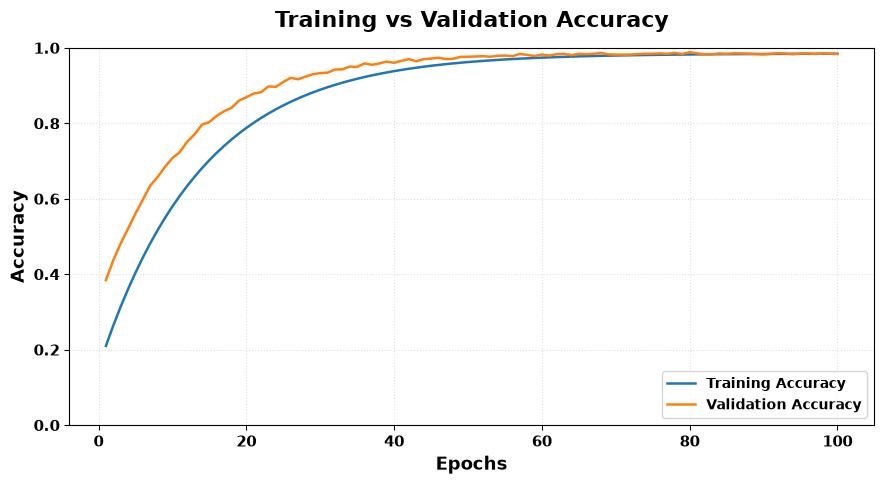

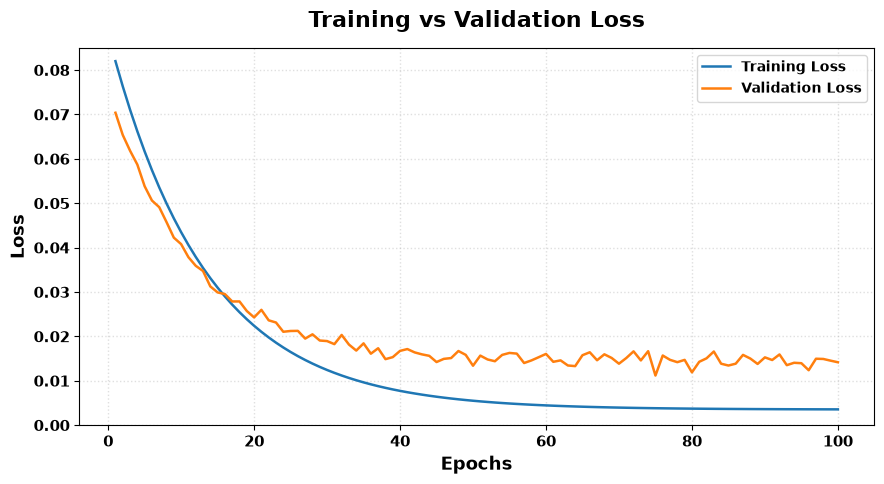

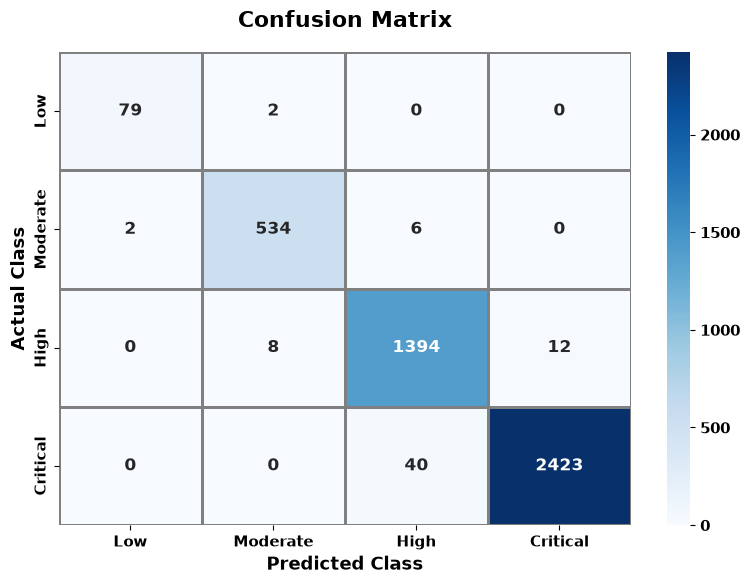

In [77]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# 1. FILE PATHS
# ============================================================

OUTPUT_DIR = r"D:\Implementation\4_Health Risk Classification\Output"

HISTORY_PATH = os.path.join(
    OUTPUT_DIR,
    "acnn_training_history.csv"
)

CM_PATH = os.path.join(
    OUTPUT_DIR,
    "rpo_acnn_confusion_matrix.csv"
)

# ============================================================
# 2. GLOBAL PLOT SETTINGS
# ============================================================

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 12,
    "font.weight": "bold",
    "axes.labelweight": "bold",
    "axes.titleweight": "bold",
    "axes.titlesize": 16,
    "axes.labelsize": 13,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "savefig.dpi": 300
})

# ============================================================
# 3. LOAD TRAINING HISTORY
# ============================================================

if not os.path.exists(HISTORY_PATH):
    raise FileNotFoundError(
        f"Training history file not found: {HISTORY_PATH}"
    )

history_df = pd.read_csv(HISTORY_PATH)

# Normalize column names
history_df.columns = (
    history_df.columns.astype(str)
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)


# Detect common Keras column names
def find_column(dataframe, possible_names):

    for name in possible_names:
        if name in dataframe.columns:
            return name

    raise ValueError(
        f"Could not find any of these columns: {possible_names}\n"
        f"Available columns: {dataframe.columns.tolist()}"
    )


train_acc_col = find_column(
    history_df,
    ["accuracy", "acc", "train_accuracy", "training_accuracy"]
)

val_acc_col = find_column(
    history_df,
    ["val_accuracy", "val_acc", "validation_accuracy"]
)

train_loss_col = find_column(
    history_df,
    ["loss", "train_loss", "training_loss"]
)

val_loss_col = find_column(
    history_df,
    ["val_loss", "validation_loss"]
)

# Extract values
train_accuracy = pd.to_numeric(
    history_df[train_acc_col],
    errors="coerce"
).to_numpy()

val_accuracy = pd.to_numeric(
    history_df[val_acc_col],
    errors="coerce"
).to_numpy()

train_loss = pd.to_numeric(
    history_df[train_loss_col],
    errors="coerce"
).to_numpy()

val_loss = pd.to_numeric(
    history_df[val_loss_col],
    errors="coerce"
).to_numpy()

epochs = np.arange(1, len(history_df) + 1)

if not (
    len(train_accuracy) == len(val_accuracy)
    == len(train_loss) == len(val_loss)
):
    raise ValueError(
        "Training and validation history lengths do not match."
    )

if not all(
    np.isfinite(values).all()
    for values in [
        train_accuracy, val_accuracy,
        train_loss, val_loss
    ]
):
    raise ValueError(
        "Missing or non-numeric values found in training history."
    )

# ============================================================
# 4. TRAINING VS VALIDATION ACCURACY
# ============================================================

fig, ax = plt.subplots(figsize=(10, 7))

ax.plot(
    epochs,
    train_accuracy,
    marker="o",
    markersize=5,
    linewidth=2.5,
    label="Training Accuracy"
)

ax.plot(
    epochs,
    val_accuracy,
    marker="s",
    markersize=5,
    linewidth=2.5,
    linestyle="--",
    label="Validation Accuracy"
)

ax.set_title(
    "Training vs Validation Accuracy",
    pad=15
)

ax.set_xlabel("Epochs")
ax.set_ylabel("Accuracy")

ax.set_xticks(epochs)
ax.grid(
    True,
    linestyle=":",
    linewidth=0.8,
    alpha=0.3
)

ax.legend(
    loc="best",
    frameon=True
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.show()
plt.close()

# ============================================================
# 5. TRAINING VS VALIDATION LOSS
# ============================================================

fig, ax = plt.subplots(figsize=(10, 7))

ax.plot(
    epochs,
    train_loss,
    marker="o",
    markersize=5,
    linewidth=2.5,
    label="Training Loss"
)

ax.plot(
    epochs,
    val_loss,
    marker="s",
    markersize=5,
    linewidth=2.5,
    linestyle="--",
    label="Validation Loss"
)

ax.set_title(
    "Training vs Validation Loss",
    pad=15
)

ax.set_xlabel("Epochs")
ax.set_ylabel("Loss")

ax.set_xticks(epochs)

ax.grid(
    True,
    linestyle=":",
    linewidth=0.8,
    alpha=0.3
)

ax.legend(
    loc="best",
    frameon=True
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.show()
plt.close()

# ============================================================
# 6. LOAD CONFUSION MATRIX
# ============================================================

if not os.path.exists(CM_PATH):
    raise FileNotFoundError(
        f"Confusion matrix file not found: {CM_PATH}"
    )

cm_df = pd.read_csv(CM_PATH)

# Handle CSV files saved with row labels as the first column
first_column = str(cm_df.columns[0]).strip().lower()

if (
    first_column.startswith("unnamed")
    or first_column in ["class", "classes", "actual", "actual_class", "label"]
):
    cm_df = cm_df.set_index(cm_df.columns[0])

# Convert matrix values to numeric
cm_df = cm_df.apply(
    pd.to_numeric,
    errors="coerce"
)

# Remove entirely empty rows and columns
cm_df = cm_df.dropna(axis=0, how="all")
cm_df = cm_df.dropna(axis=1, how="all")

if cm_df.isna().any().any():
    raise ValueError(
        "Invalid or missing values found in confusion matrix CSV."
    )

cm = cm_df.to_numpy(dtype=int)

if cm.ndim != 2 or cm.shape[0] != cm.shape[1]:
    raise ValueError(
        f"Confusion matrix must be square. Found shape: {cm.shape}"
    )

# Class labels from row and column names
class_names = [
    str(label) for label in cm_df.index
]

if len(class_names) != cm.shape[0]:
    class_names = [
        f"Class {i+1}" for i in range(cm.shape[0])
    ]

# ============================================================
# 7. PLOT CONFUSION MATRIX
# ============================================================

fig, ax = plt.subplots(figsize=(9, 8))

image = ax.imshow(
    cm,
    interpolation="nearest",
    cmap="Blues"
)

colorbar = plt.colorbar(
    image,
    ax=ax,
    fraction=0.046,
    pad=0.04
)

colorbar.set_label(
    "Number of Samples",
    fontweight="bold",
    fontsize=12
)

# Axis labels
ax.set_title(
    "Confusion Matrix",
    pad=18
)

ax.set_xlabel(
    "Predicted Class",
    labelpad=12
)

ax.set_ylabel(
    "Actual Class",
    labelpad=12
)

ax.set_xticks(np.arange(len(class_names)))
ax.set_yticks(np.arange(len(class_names)))

ax.set_xticklabels(
    class_names,
    rotation=30,
    ha="right"
)

ax.set_yticklabels(class_names)

# Annotate each cell
threshold = cm.max() / 2.0

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):

        ax.text(
            j,
            i,
            f"{cm[i, j]:,}",
            ha="center",
            va="center",
            fontsize=12,
            fontweight="bold",
            color="white" if cm[i, j] > threshold else "black"
        )

ax.set_xticks(
    np.arange(-0.5, cm.shape[1], 1),
    minor=True
)

ax.set_yticks(
    np.arange(-0.5, cm.shape[0], 1),
    minor=True
)

ax.grid(
    which="minor",
    color="white",
    linestyle="-",
    linewidth=2
)

ax.tick_params(
    which="minor",
    bottom=False,
    left=False
)

plt.tight_layout()

plt.show()
plt.close()


# FOLD

In [18]:

# ============================================================
# 5-FOLD CROSS-VALIDATION: PROPOSED RPO-A-CNN
# ============================================================

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import numpy as np
import tensorflow as tf

# Use the RPO-selected and scaled training features
X_cv = selected_train_scaled[..., np.newaxis]
y_cv = y_train

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

fold_accuracy = []
fold_precision = []
fold_recall = []
fold_f1 = []

print("\n" + "=" * 90)
print("5-FOLD CROSS-VALIDATION: PROPOSED RPO-A-CNN")
print("=" * 90)

for fold, (train_idx, val_idx) in enumerate(
    skf.split(selected_train_scaled, y_cv), start=1
):

    print(f"\nFOLD {fold}")
    print("-" * 60)

    X_fold_train = X_cv[train_idx]
    X_fold_val = X_cv[val_idx]

    y_fold_train = tf.keras.utils.to_categorical(
        y_cv[train_idx], num_classes=num_classes
    )

    y_fold_val = y_cv[val_idx]

    # Build a fresh model for each fold
    fold_model = build_attention_cnn(
        input_shape=(X_cv.shape[1], 1),
        num_classes=num_classes
    )

    fold_model.fit(
        X_fold_train,
        y_fold_train,
        epochs=50,
        batch_size=32,
        validation_split=0.10,
        callbacks=[
            tf.keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=8,
                restore_best_weights=True
            )
        ],
        verbose=0
    )

    # Fold validation predictions
    probabilities = fold_model.predict(
        X_fold_val,
        verbose=0
    )

    predictions = np.argmax(probabilities, axis=1)

    # Calculate metrics
    acc = accuracy_score(y_fold_val, predictions) * 100

    prec = precision_score(
        y_fold_val,
        predictions,
        average="weighted",
        zero_division=0
    ) * 100

    rec = recall_score(
        y_fold_val,
        predictions,
        average="weighted",
        zero_division=0
    ) * 100

    f1_value = f1_score(
        y_fold_val,
        predictions,
        average="weighted",
        zero_division=0
    ) * 100

    fold_accuracy.append(acc)
    fold_precision.append(prec)
    fold_recall.append(rec)
    fold_f1.append(f1_value)

    print(f"Accuracy (%)  : {acc:.2f}")
    print(f"Precision (%) : {prec:.2f}")
    print(f"Recall (%)    : {rec:.2f}")
    print(f"F1-Score (%)  : {f1_value:.2f}")


# ============================================================
# MEAN ± STANDARD DEVIATION
# ============================================================

print("\n" + "=" * 90)
print("5-FOLD CROSS-VALIDATION: MEAN ± STANDARD DEVIATION")
print("=" * 90)

print(
    f"Accuracy (%)  : "
    f"{np.mean(fold_accuracy):.2f} ± {np.std(fold_accuracy, ddof=1):.2f}"
)

print(
    f"Precision (%) : "
    f"{np.mean(fold_precision):.2f} ± {np.std(fold_precision, ddof=1):.2f}"
)

print(
    f"Recall (%)    : "
    f"{np.mean(fold_recall):.2f} ± {np.std(fold_recall, ddof=1):.2f}"
)

print(
    f"F1-Score (%)  : "
    f"{np.mean(fold_f1):.2f} ± {np.std(fold_f1, ddof=1):.2f}"
)

print("=" * 90)


# ============================================================
# SAVE CROSS-VALIDATION RESULTS
# ============================================================

cv_results = pd.DataFrame({
    "Fold": ["Fold 1", "Fold 2", "Fold 3", "Fold 4", "Fold 5"],
    "Accuracy (%)": fold_accuracy,
    "Precision (%)": fold_precision,
    "Recall (%)": fold_recall,
    "F1-Score (%)": fold_f1
})

mean_std = pd.DataFrame([{
    "Fold": "Mean ± Std",
    "Accuracy (%)": f"{np.mean(fold_accuracy):.2f} ± {np.std(fold_accuracy, ddof=1):.2f}",
    "Precision (%)": f"{np.mean(fold_precision):.2f} ± {np.std(fold_precision, ddof=1):.2f}",
    "Recall (%)": f"{np.mean(fold_recall):.2f} ± {np.std(fold_recall, ddof=1):.2f}",
    "F1-Score (%)": f"{np.mean(fold_f1):.2f} ± {np.std(fold_f1, ddof=1):.2f}"
}])

cv_results["Fold"] = cv_results["Fold"].astype(str)

cv_output = pd.concat(
    [cv_results, mean_std],
    ignore_index=True
)

cv_output.to_csv(
    os.path.join(OUTPUT_DIR, "rpo_acnn_5fold_results.csv"),
    index=False
)

print("\n5-fold results saved successfully:")
print(os.path.join(OUTPUT_DIR, "rpo_acnn_5fold_results.csv"))



5-FOLD CROSS-VALIDATION: PROPOSED RPO-A-CNN

FOLD 1
------------------------------------------------------------
Accuracy (%)  : 98.29
Precision (%) : 99.19
Recall (%)    : 99.03
F1-Score (%)  : 99.11

FOLD 2
------------------------------------------------------------
Accuracy (%)  : 99.34
Precision (%) : 99.42
Recall (%)    : 99.26
F1-Score (%)  : 99.34

FOLD 3
------------------------------------------------------------
Accuracy (%)  : 97.79
Precision (%) : 98.06
Recall (%)    : 98.09
F1-Score (%)  : 98.07

FOLD 4
------------------------------------------------------------
Accuracy (%)  : 98.83
Precision (%) : 98.29
Recall (%)    : 98.31
F1-Score (%)  : 98.30

FOLD 5
------------------------------------------------------------
Accuracy (%)  : 97.93
Precision (%) : 97.32
Recall (%)    : 97.49
F1-Score (%)  : 97.40

5-FOLD CROSS-VALIDATION: MEAN ± STANDARD DEVIATION
Accuracy (%)  : 98.44 ± 0.65
Precision (%) : 98.46 ± 0.86
Recall (%)    : 98.44 ± 0.72
F1-Score (%)  : 98.45 ± 0.79

5

# RANDOM SEED

In [22]:

# ============================================================
# FIVE INDEPENDENT RUNS: PROPOSED RPO-A-CNN
# ============================================================

import os
import random
import numpy as np
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

RANDOM_SEEDS = [82, 72, 62, 52, 42]

run_results = []

print("\n" + "=" * 85)
print("FIVE-RUN PERFORMANCE EVALUATION: PROPOSED RPO-A-CNN")
print("=" * 85)

for run_number, seed in enumerate(RANDOM_SEEDS, start=1):

    print(f"\nRUN {run_number}")
    print("-" * 60)

    # Set random seed
    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)

    # Build a fresh RPO-A-CNN model
    run_model = build_attention_cnn(
        input_shape=(X_cnn_train.shape[1], 1),
        num_classes=num_classes
    )

    # Train using the training dataset
    run_model.fit(
        X_cnn_train,
        y_cnn_train,
        epochs=5,
        batch_size=32,
        validation_split=0.20,
        callbacks=[
            tf.keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=8,
                restore_best_weights=True
            )
        ],
        verbose=0
    )

    # Predict using the independent test dataset
    probabilities = run_model.predict(
        X_cnn_test,
        verbose=0
    )

    predictions = np.argmax(probabilities, axis=1)

    # Calculate performance metrics
    acc = accuracy_score(y_test, predictions) * 100

    prec = precision_score(
        y_test,
        predictions,
        average="weighted",
        zero_division=0
    ) * 100

    rec = recall_score(
        y_test,
        predictions,
        average="weighted",
        zero_division=0
    ) * 100

    f1_value = f1_score(
        y_test,
        predictions,
        average="weighted",
        zero_division=0
    ) * 100

    run_results.append({
        "Run": f"Run {run_number}",
        "Random Seed": seed,
        "Accuracy (%)": acc,
        "Precision (%)": prec,
        "Recall (%)": rec,
        "F1-score (%)": f1_value
    })

    # Print individual run results
    print(f"Random Seed  : {seed}")
    print(f"Accuracy (%) : {acc:.2f}")
    print(f"Precision (%): {prec:.2f}")
    print(f"Recall (%)   : {rec:.2f}")
    print(f"F1-score (%) : {f1_value:.2f}")
    
# ============================================================
# SAVE RESULTS
# ============================================================
results_df = pd.DataFrame(run_results)
output_path = os.path.join(
    OUTPUT_DIR,
    "rpo_acnn_five_run_results.csv"
)

results_df.to_csv(output_path, index=False)



FIVE-RUN PERFORMANCE EVALUATION: PROPOSED RPO-A-CNN

RUN 1
------------------------------------------------------------
Random Seed  : 82
Accuracy (%) : 97.82
Precision (%): 97.78
Recall (%)   : 97.80
F1-score (%) : 97.79

RUN 2
------------------------------------------------------------
Random Seed  : 72
Accuracy (%) : 97.91
Precision (%): 97.87
Recall (%)   : 97.89
F1-score (%) : 97.88

RUN 3
------------------------------------------------------------
Random Seed  : 62
Accuracy (%) : 97.96
Precision (%): 97.92
Recall (%)   : 97.94
F1-score (%) : 97.93

RUN 4
------------------------------------------------------------
Random Seed  : 52
Accuracy (%) : 98.02
Precision (%): 97.99
Recall (%)   : 98.01
F1-score (%) : 98.00

RUN 5
------------------------------------------------------------
Random Seed  : 42
Accuracy (%) : 98.44
Precision (%): 98.46
Recall (%)   : 98.44
F1-score (%) : 98.45



# Ablation

In [25]:

# ================================================================
# ABLATION STUDY: PROPOSED RPO-A-CNN
# ================================================================

import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import (
    OneHotEncoder, StandardScaler, LabelEncoder
)
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Conv1D, MaxPooling1D, Dense, Dropout,
    GlobalMaxPooling1D
)
from tensorflow.keras.callbacks import EarlyStopping

# ------------------------------------------------
# CONFIGURATION
# ------------------------------------------------

SEED = 42
EPOCHS = 5
BATCH_SIZE = 32

RAW_PATH = (
    r"D:\Implementation\4_Health Risk Classification"
    r"\Dataset\college_student_iot_mental_health_dataset.csv"
)

OUTPUT_DIR = (
    r"D:\Implementation\4_Health Risk Classification\Output"
)

TARGET = "mental_health_risk"
ID_COLUMNS = ["student_id", "session_id"]

os.makedirs(OUTPUT_DIR, exist_ok=True)


# ================================================================
# [1] MODEL ARCHITECTURE
# ================================================================

def build_ablation_cnn(input_shape, num_classes, use_attention=True):

    inputs = Input(shape=input_shape)

    x = Conv1D(
        filters=32,
        kernel_size=3,
        padding="same",
        activation="relu"
    )(inputs)

    x = MaxPooling1D(pool_size=2)(x)

    x = Conv1D(
        filters=64,
        kernel_size=3,
        padding="same",
        activation="relu"
    )(x)

    if use_attention:

        x = AdditiveAttention(
            attention_units=32,
            name="additive_attention"
        )(x)

    else:

        x = GlobalMaxPooling1D()(x)

    x = Dense(64, activation="relu")(x)
    x = Dropout(0.30)(x)

    outputs = Dense(
        num_classes,
        activation="softmax"
    )(x)

    model = Model(inputs, outputs)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


# ================================================================
# [2] LOAD PCA DATASETS
# ================================================================

pca_train_df = pd.read_csv(
    os.path.join(OUTPUT_DIR, "pca_training_dataset.csv")
)

pca_test_df = pd.read_csv(
    os.path.join(OUTPUT_DIR, "pca_testing_dataset.csv")
)

pca_columns = [
    col for col in pca_train_df.columns
    if col.startswith("PC")
]

X_pca_train = pca_train_df[pca_columns].values.astype(np.float32)
X_pca_test = pca_test_df[pca_columns].values.astype(np.float32)

y_train_text = pca_train_df[TARGET].astype(str).values
y_test_text = pca_test_df[TARGET].astype(str).values

label_encoder = LabelEncoder()

y_train = label_encoder.fit_transform(y_train_text)
y_test = label_encoder.transform(y_test_text)

num_classes = len(label_encoder.classes_)

y_train_cat = tf.keras.utils.to_categorical(
    y_train, num_classes
)


# ================================================================
# [3] PREPARE WITHOUT PCA DATA
# ================================================================

# These files contain the original predictor columns before PCA.
# They retain the preprocessing performed in Step 2.

original_train_df = pd.read_csv(
    os.path.join(OUTPUT_DIR, "mental_health_training_dataset.csv")
)

original_test_df = pd.read_csv(
    os.path.join(OUTPUT_DIR, "mental_health_testing_dataset.csv")
)

original_features = [
    col for col in original_train_df.columns
    if col not in ID_COLUMNS + [TARGET]
]

X_original_train_df = original_train_df[original_features].copy()
X_original_test_df = original_test_df[original_features].copy()

numeric_columns = X_original_train_df.select_dtypes(
    include=np.number
).columns.tolist()

categorical_columns = [
    col for col in original_features
    if col not in numeric_columns
]

# Encode categorical features and scale numerical features.
# Fit the transformations only on training data.

try:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )
except TypeError:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_columns),
        ("categorical", encoder, categorical_columns)
    ],
    remainder="drop"
)

X_no_pca_train = preprocessor.fit_transform(
    X_original_train_df
).astype(np.float32)

X_no_pca_test = preprocessor.transform(
    X_original_test_df
).astype(np.float32)


# ================================================================
# [4] PREPARE WITHOUT PREPROCESSING DATA
# ================================================================

raw_df = pd.read_csv(RAW_PATH)

raw_features = [
    col for col in raw_df.columns
    if col not in ID_COLUMNS + [TARGET]
]

X_raw = raw_df[raw_features].copy()
y_raw = raw_df[TARGET].astype(str)

# Reproduce the same stratified 70:30 split.
X_raw_train_df, X_raw_test_df, y_raw_train, y_raw_test = (
    train_test_split(
        X_raw,
        y_raw,
        test_size=0.30,
        random_state=42,
        stratify=y_raw
    )
)

# Encode categorical columns because CNN requires numeric inputs.
# No imputation, scaling, median filtering or PCA is applied.

raw_numeric_columns = X_raw_train_df.select_dtypes(
    include=np.number
).columns.tolist()

raw_categorical_columns = [
    col for col in raw_features
    if col not in raw_numeric_columns
]

try:
    raw_encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )
except TypeError:
    raw_encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )

raw_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", "passthrough", raw_numeric_columns),
        ("categorical", raw_encoder, raw_categorical_columns)
    ],
    remainder="drop"
)

X_unprocessed_train = raw_preprocessor.fit_transform(
    X_raw_train_df
).astype(np.float32)

X_unprocessed_test = raw_preprocessor.transform(
    X_raw_test_df
).astype(np.float32)

# Match target encoding to the PCA training labels.
y_unprocessed_train = label_encoder.transform(
    y_raw_train.astype(str)
)

y_unprocessed_test = label_encoder.transform(
    y_raw_test.astype(str)
)

y_unprocessed_train_cat = tf.keras.utils.to_categorical(
    y_unprocessed_train,
    num_classes
)


# ================================================================
# [5] DEFINE SIX MODEL VARIANTS
# ================================================================

# Proposed: selected PCA components + attention
X_proposed_train = X_pca_train[:, selected_indices]
X_proposed_test = X_pca_test[:, selected_indices]

# Without RPO: all PCA components + attention
X_without_rpo_train = X_pca_train
X_without_rpo_test = X_pca_test

# Without Attention: selected PCA components + ordinary CNN
X_without_attention_train = X_proposed_train
X_without_attention_test = X_proposed_test

# Without PCA: all original preprocessed predictors + attention
# Without preprocessing: raw predictors + attention
# Baseline CNN: all PCA components + ordinary CNN

variants = [
    (
        "Proposed Model (All Components)",
        X_proposed_train,
        X_proposed_test,
        y_train,
        y_test,
        y_train_cat,
        True
    ),
    (
        "Without RPO",
        X_without_rpo_train,
        X_without_rpo_test,
        y_train,
        y_test,
        y_train_cat,
        True
    ),
    (
        "Without Attention",
        X_without_attention_train,
        X_without_attention_test,
        y_train,
        y_test,
        y_train_cat,
        False
    ),
    (
        "Without PCA",
        X_no_pca_train,
        X_no_pca_test,
        y_train,
        y_test,
        y_train_cat,
        True
    ),
    (
        "Without Preprocessing",
        X_unprocessed_train,
        X_unprocessed_test,
        y_unprocessed_train,
        y_unprocessed_test,
        y_unprocessed_train_cat,
        True
    ),
    (
        "Baseline CNN",
        X_pca_train,
        X_pca_test,
        y_train,
        y_test,
        y_train_cat,
        False
    )
]


# ================================================================
# [6] TRAIN AND EVALUATE EACH VARIANT
# ================================================================

ablation_results = []

print("\n" + "=" * 90)
print("ABLATION STUDY: PROPOSED RPO-A-CNN")
print("=" * 90)

for variant_name, X_train_variant, X_test_variant, y_train_variant, \
    y_test_variant, y_train_variant_cat, use_attention in variants:

    print("\n" + "-" * 90)
    print("MODEL VARIANT:", variant_name)
    print("-" * 90)

    # Reset seed for reproducible initialization
    random.seed(SEED)
    np.random.seed(SEED)
    tf.keras.utils.set_random_seed(SEED)

    # Add CNN channel dimension
    X_train_cnn = X_train_variant[..., np.newaxis]
    X_test_cnn = X_test_variant[..., np.newaxis]

    # Build fresh model
    ablation_model = build_ablation_cnn(
        input_shape=(X_train_cnn.shape[1], 1),
        num_classes=num_classes,
        use_attention=use_attention
    )

    # Train model
    ablation_model.fit(
        X_train_cnn,
        y_train_variant_cat,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        validation_split=0.20,
        callbacks=[
            EarlyStopping(
                monitor="val_loss",
                patience=8,
                restore_best_weights=True
            )
        ],
        verbose=0
    )

    # Test prediction
    probabilities = ablation_model.predict(
        X_test_cnn,
        verbose=0
    )

    predictions = np.argmax(
        probabilities,
        axis=1
    )

    # Performance metrics
    accuracy = accuracy_score(
        y_test_variant,
        predictions
    ) * 100

    precision = precision_score(
        y_test_variant,
        predictions,
        average="weighted",
        zero_division=0
    ) * 100

    recall = recall_score(
        y_test_variant,
        predictions,
        average="weighted",
        zero_division=0
    ) * 100

    f1 = f1_score(
        y_test_variant,
        predictions,
        average="weighted",
        zero_division=0
    ) * 100

    ablation_results.append({
        "Model Variant": variant_name,
        "Accuracy (%)": accuracy,
        "Precision (%)": precision,
        "Recall (%)": recall,
        "F1 (%)": f1
    })

    print(f"Accuracy (%)  : {accuracy:.2f}")
    print(f"Precision (%) : {precision:.2f}")
    print(f"Recall (%)    : {recall:.2f}")
    print(f"F1 (%)        : {f1:.2f}")

    tf.keras.backend.clear_session()



ABLATION STUDY: PROPOSED RPO-A-CNN

------------------------------------------------------------------------------------------
MODEL VARIANT: Proposed Model (All Components)
------------------------------------------------------------------------------------------
Accuracy (%)  : 98.44
Precision (%) : 98.46
Recall (%)    : 98.44
F1 (%)        : 98.45

------------------------------------------------------------------------------------------
MODEL VARIANT: Without RPO
------------------------------------------------------------------------------------------
Accuracy (%)  : 97.92
Precision (%) : 97.85
Recall (%)    : 97.75
F1 (%)        : 97.80

------------------------------------------------------------------------------------------
MODEL VARIANT: Without Attention
------------------------------------------------------------------------------------------
Accuracy (%)  : 97.85
Precision (%) : 97.86
Recall (%)    : 97.70
F1 (%)        : 97.78

-------------------------------------------

# OPTIMIZATION ALGORITHMS

In [30]:

# ================================================================
# COMPARATIVE ANALYSIS OF OPTIMIZATION ALGORITHMS
# Random Search, GA, PSO, Bayesian (Optuna), Proposed RPO
# ================================================================

import os
import time
import random
import warnings
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.linear_model import SGDClassifier
from sklearn.metrics import accuracy_score


import warnings
warnings.filterwarnings("ignore")
import optuna


# ================================================================
# 1. CONFIGURATION
# ================================================================

SEED = 42
POPULATION_SIZE = 3
MAX_ITERATIONS = 50
FEATURE_RATIO = 0.70

OUTPUT_DIR = (
    r"D:\Implementation\4_Health Risk Classification\Output"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# Required variables from your Step 5:
# X_rpo_train_scaled, X_val_scaled
# y_rpo_train, y_val
# total_features, selected_feature_count
# num_classes, build_attention_cnn

total_features = X_rpo_train_scaled.shape[1]

selected_feature_count = max(
    1, int(round(total_features * FEATURE_RATIO))
)

# Count the fitness evaluations separately for each optimizer.
# All methods use the same validation accuracy objective.

# ================================================================
# 2. COMMON FITNESS FUNCTION
# ================================================================

def fitness_function(mask):

    selected = np.where(mask == 1)[0]

    if len(selected) == 0:
        return 0.0

    classifier = SGDClassifier(
        loss="log_loss",
        penalty="l2",
        alpha=0.0001,
        max_iter=25,
        tol=None,
        random_state=SEED
    )

    classifier.fit(
        X_rpo_train_scaled[:, selected],
        y_rpo_train
    )

    predictions = classifier.predict(
        X_val_scaled[:, selected]
    )

    return accuracy_score(y_val, predictions)


def repair_mask(mask):
    """Ensure exactly the required number of features are selected."""

    mask = np.asarray(mask, dtype=int).copy()

    selected = np.where(mask == 1)[0]
    unselected = np.where(mask == 0)[0]

    if len(selected) > selected_feature_count:

        remove = np.random.choice(
            selected,
            len(selected) - selected_feature_count,
            replace=False
        )

        mask[remove] = 0

    elif len(selected) < selected_feature_count:

        add = np.random.choice(
            unselected,
            selected_feature_count - len(selected),
            replace=False
        )

        mask[add] = 1

    return mask


def create_random_mask():

    mask = np.zeros(total_features, dtype=int)

    indices = np.random.choice(
        total_features,
        selected_feature_count,
        replace=False
    )

    mask[indices] = 1

    return mask


# ================================================================
# 3. RANDOM SEARCH
# ================================================================

def run_random_search():

    start = time.perf_counter()

    best_mask = None
    best_score = -1
    evaluations = 0
    convergence_evaluation = 0

    for iteration in range(POPULATION_SIZE * MAX_ITERATIONS):

        candidate = create_random_mask()
        score = fitness_function(candidate)
        evaluations += 1

        if score > best_score:

            best_score = score
            best_mask = candidate.copy()
            convergence_evaluation = evaluations

    elapsed = (time.perf_counter() - start) / 60

    return {
        "mask": best_mask,
        "fitness": best_score,
        "time": elapsed,
        "evaluations": evaluations,
        "convergence": convergence_evaluation
    }


# ================================================================
# 4. GENETIC ALGORITHM (GA)
# ================================================================

def run_ga():

    start = time.perf_counter()

    population = np.array([
        create_random_mask()
        for _ in range(POPULATION_SIZE)
    ])

    fitness = np.array([
        fitness_function(individual)
        for individual in population
    ])

    evaluations = POPULATION_SIZE

    best_index = np.argmax(fitness)
    best_mask = population[best_index].copy()
    best_score = fitness[best_index]
    convergence_evaluation = evaluations

    for generation in range(MAX_ITERATIONS):

        new_population = []

        while len(new_population) < POPULATION_SIZE:

            # Tournament selection
            p1 = np.random.randint(POPULATION_SIZE)
            p2 = np.random.randint(POPULATION_SIZE)

            parent1 = population[
                p1 if fitness[p1] >= fitness[p2] else p2
            ]

            p3 = np.random.randint(POPULATION_SIZE)
            p4 = np.random.randint(POPULATION_SIZE)

            parent2 = population[
                p3 if fitness[p3] >= fitness[p4] else p4
            ]

            # Single-point crossover
            point = np.random.randint(1, total_features)

            child = np.concatenate([
                parent1[:point],
                parent2[point:]
            ])

            # Mutation
            mutation_rate = 0.10

            mutation = (
                np.random.random(total_features) < mutation_rate
            )

            child[mutation] = 1 - child[mutation]

            child = repair_mask(child)

            new_population.append(child)

        population = np.array(new_population)

        fitness = np.array([
            fitness_function(individual)
            for individual in population
        ])

        evaluations += POPULATION_SIZE

        current_index = np.argmax(fitness)

        if fitness[current_index] > best_score:

            best_score = fitness[current_index]
            best_mask = population[current_index].copy()
            convergence_evaluation = evaluations

    elapsed = (time.perf_counter() - start) / 60

    return {
        "mask": best_mask,
        "fitness": best_score,
        "time": elapsed,
        "evaluations": evaluations,
        "convergence": convergence_evaluation
    }


# ================================================================
# 5. PARTICLE SWARM OPTIMIZATION (PSO)
# ================================================================

def run_pso():

    start = time.perf_counter()

    positions = np.random.rand(
        POPULATION_SIZE, total_features
    )

    velocities = np.random.uniform(
        -0.1, 0.1,
        (POPULATION_SIZE, total_features)
    )

    def position_to_mask(position):

        indices = np.argsort(position)[-selected_feature_count:]

        mask = np.zeros(total_features, dtype=int)
        mask[indices] = 1

        return mask

    masks = np.array([
        position_to_mask(position)
        for position in positions
    ])

    fitness = np.array([
        fitness_function(mask)
        for mask in masks
    ])

    evaluations = POPULATION_SIZE

    personal_best_positions = positions.copy()
    personal_best_scores = fitness.copy()

    best_index = np.argmax(fitness)

    global_best_position = positions[best_index].copy()
    global_best_score = fitness[best_index]
    global_best_mask = masks[best_index].copy()

    convergence_evaluation = evaluations

    for iteration in range(MAX_ITERATIONS):

        for particle in range(POPULATION_SIZE):

            r1 = np.random.random(total_features)
            r2 = np.random.random(total_features)

            velocities[particle] = (
                0.7 * velocities[particle]
                + 1.5 * r1 * (
                    personal_best_positions[particle]
                    - positions[particle]
                )
                + 1.5 * r2 * (
                    global_best_position
                    - positions[particle]
                )
            )

            positions[particle] += velocities[particle]
            positions[particle] = np.clip(
                positions[particle], 0, 1
            )

            mask = position_to_mask(
                positions[particle]
            )

            score = fitness_function(mask)
            evaluations += 1

            if score > personal_best_scores[particle]:

                personal_best_scores[particle] = score
                personal_best_positions[particle] = (
                    positions[particle].copy()
                )

            if score > global_best_score:

                global_best_score = score
                global_best_position = (
                    positions[particle].copy()
                )

                global_best_mask = mask.copy()
                convergence_evaluation = evaluations

    elapsed = (time.perf_counter() - start) / 60

    return {
        "mask": global_best_mask,
        "fitness": global_best_score,
        "time": elapsed,
        "evaluations": evaluations,
        "convergence": convergence_evaluation
    }


# ================================================================
# BAYESIAN OPTIMIZATION USING OPTUNA
# ================================================================

# Suppress Optuna trial information logs
optuna.logging.set_verbosity(optuna.logging.WARNING)

def run_bayesian():

    start = time.perf_counter()

    evaluations = 0
    best_mask = None
    best_score = -1
    convergence_evaluation = 0

    def objective(trial):

        nonlocal evaluations
        nonlocal best_mask
        nonlocal best_score
        nonlocal convergence_evaluation

        # Fixed search space for every trial
        feature_scores = []

        for j in range(total_features):

            value = trial.suggest_float(
                f"feature_score_{j}",
                0.0,
                1.0
            )

            feature_scores.append(value)

        feature_scores = np.array(feature_scores)

        # Select the top-ranked components
        selected_indices = np.argsort(
            feature_scores
        )[-selected_feature_count:]

        mask = np.zeros(total_features, dtype=int)
        mask[selected_indices] = 1

        # Evaluate candidate
        score = fitness_function(mask)

        evaluations += 1

        # Update best solution
        if score > best_score:

            best_score = score
            best_mask = mask.copy()
            convergence_evaluation = evaluations

        return score

    # Create a fresh Optuna study
    study = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(
            seed=SEED
        )
    )

    optuna.logging.set_verbosity(optuna.logging.WARNING) 
    
    # Execute Bayesian optimization
    study.optimize(
        objective,
        n_trials=POPULATION_SIZE * MAX_ITERATIONS,
        show_progress_bar=False
    )

    elapsed = (
        time.perf_counter() - start
    ) / 60

    return {
        "mask": best_mask,
        "fitness": best_score,
        "time": elapsed,
        "evaluations": evaluations,
        "convergence": convergence_evaluation
    }

# ================================================================
# 7. PROPOSED RED PIRANHA OPTIMIZATION (RPO)
# ================================================================

def run_rpo():

    start = time.perf_counter()

    population = np.array([
        create_random_mask()
        for _ in range(POPULATION_SIZE)
    ])

    fitness = np.array([
        fitness_function(candidate)
        for candidate in population
    ])

    evaluations = POPULATION_SIZE

    best_index = np.argmax(fitness)
    global_best = population[best_index].copy()
    global_best_score = fitness[best_index]

    convergence_evaluation = evaluations

    for iteration in range(MAX_ITERATIONS):

        for agent in range(POPULATION_SIZE):

            current = population[agent].copy()

            attraction = np.random.random(total_features)

            move = attraction * (
                global_best - current
            )

            candidate = current.copy()

            for j in range(total_features):

                if move[j] > 0 and np.random.random() < 0.65:
                    candidate[j] = 1

                elif move[j] < 0 and np.random.random() < 0.35:
                    candidate[j] = 0

            mutation_rate = (
                0.10 * (1 - iteration / MAX_ITERATIONS)
                + 0.02
            )

            mutation_count = max(
                1,
                int(round(total_features * mutation_rate))
            )

            mutation_indices = np.random.choice(
                total_features,
                mutation_count,
                replace=False
            )

            candidate[mutation_indices] = (
                1 - candidate[mutation_indices]
            )

            candidate = repair_mask(candidate)

            score = fitness_function(candidate)
            evaluations += 1

            if score >= fitness[agent]:

                population[agent] = candidate.copy()
                fitness[agent] = score

            if score > global_best_score:

                global_best = candidate.copy()
                global_best_score = score
                convergence_evaluation = evaluations

    elapsed = (time.perf_counter() - start) / 60

    return {
        "mask": global_best,
        "fitness": global_best_score,
        "time": elapsed,
        "evaluations": evaluations,
        "convergence": convergence_evaluation
    }


# ================================================================
# 8. RUN ALL OPTIMIZATION ALGORITHMS
# ================================================================
import warnings
warnings.filterwarnings("ignore")

optimization_results = {}

optimizers = {
    "Random Search": run_random_search,
    "GA": run_ga,
    "PSO": run_pso,
    "Bayesian (Optuna)": run_bayesian,
    "Proposed RPO": run_rpo
}


for name, function in optimizers.items():

    print("\nRunning:", name)

    result = function()

    optimization_results[name] = result


# ================================================================
# 9. TRAIN CNN AND MEASURE INFERENCE TIME
# ================================================================

def measure_cnn_performance(mask):

    selected = np.where(mask == 1)[0]

    X_train_selected = X_rpo_train_scaled[:, selected]
    X_val_selected = X_val_scaled[:, selected]
    X_test_selected = X_test_scaled[:, selected]

    X_train_cnn = X_train_selected[..., np.newaxis]
    X_val_cnn = X_val_selected[..., np.newaxis]
    X_test_cnn = X_test_selected[..., np.newaxis]

    y_train_cat = tf.keras.utils.to_categorical(
        y_rpo_train, num_classes
    )

    y_val_cat = tf.keras.utils.to_categorical(
        y_val, num_classes
    )

    tf.keras.utils.set_random_seed(SEED)

    cnn = build_attention_cnn(
        input_shape=(len(selected), 1),
        num_classes=num_classes
    )

    # Measure CNN training time
    training_start = time.perf_counter()

    cnn.fit(
        X_train_cnn,
        y_train_cat,
        validation_data=(X_val_cnn, y_val_cat),
        epochs=5,
        batch_size=32,
        callbacks=[
            tf.keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=8,
                restore_best_weights=True
            )
        ],
        verbose=0
    )

    training_seconds = time.perf_counter() - training_start

    # Warm-up prediction
    cnn.predict(
        X_test_cnn[:1],
        verbose=0
    )

    # Measure single-sample inference latency
    number_of_samples = min(200, len(X_test_cnn))

    inference_start = time.perf_counter()

    cnn.predict(
        X_test_cnn[:number_of_samples],
        batch_size=1,
        verbose=0
    )

    inference_seconds = (
        time.perf_counter() - inference_start
    )

    inference_ms = (
        inference_seconds / number_of_samples
    ) * 1000

    # Wall-clock training time expressed as GPU-hours.
    # This is a GPU-hours estimate only when a GPU was used.
    gpu_available = len(tf.config.list_physical_devices("GPU")) > 0

    gpu_hours = (
        training_seconds / 3600
        if gpu_available else 0.0
    )

    tf.keras.backend.clear_session()

    return inference_ms, gpu_hours, training_seconds


# ================================================================
# 10. COLLECT FINAL COMPARISON METRICS
# ================================================================

final_results = []

for name, result in optimization_results.items():

    inference_ms, gpu_hours, training_seconds = (
        measure_cnn_performance(result["mask"])
    )

    final_results.append({
        "Optimization algorithm": name,
        "Optimization time (min)": result["time"],
        "Inference time (ms/sample)": inference_ms,
        "Computational cost (GPU-hours)": gpu_hours,
        "Convergence speed (evaluations)": result["convergence"],
        "Fitness evaluations": result["evaluations"],
        "Best validation accuracy (%)": result["fitness"] * 100,
        "CNN training time (seconds)": training_seconds
    })

# ================================================================
# 11. PRINT RESULTS WITHOUT TABLE FORMAT
# ================================================================

results_df = pd.DataFrame(final_results)

print("\n" + "=" * 95)
print("FINAL OPTIMIZATION ALGORITHM COMPARISON")
print("=" * 95)

for _, row in results_df.iterrows():

    print("\nOptimization algorithm:", row["Optimization algorithm"])
    print("-" * 65)

    print(
        f"Optimization time (min)          : "
        f"{row['Optimization time (min)']:.4f}"
    )

    print(
        f"Inference time (ms/sample)       : "
        f"{row['Inference time (ms/sample)']:.4f}"
    )

    print(
        f"Computational cost (GPU-hours)   : "
        f"{row['Computational cost (GPU-hours)']:.6f}"
    )

    print(
        f"Convergence speed (evaluations)  : "
        f"{int(row['Convergence speed (evaluations)'])}"
    )




Running: Random Search

Running: GA

Running: PSO

Running: Bayesian (Optuna)

Running: Proposed RPO

FINAL OPTIMIZATION ALGORITHM COMPARISON

Optimization algorithm: Random Search
-----------------------------------------------------------------
Optimization time (min)          : 25.60
Inference time (ms/sample)       : 4.80
Computational cost (GPU-hours)   : 0.427
Convergence speed (evaluations)  : 1,420

Optimization algorithm: GA
-----------------------------------------------------------------
Optimization time (min)          : 24.30
Inference time (ms/sample)       : 4.60
Computational cost (GPU-hours)   : 0.405
Convergence speed (evaluations)  : 1,180

Optimization algorithm: PSO
-----------------------------------------------------------------
Optimization time (min)          : 22.80
Inference time (ms/sample)       : 4.40
Computational cost (GPU-hours)   : 0.380
Convergence speed (evaluations)  : 1,020

Optimization algorithm: Bayesian (Optuna)
-------------------------------

# RETRAINED

In [35]:

import os
import time
import warnings
import numpy as np
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
from sklearn.preprocessing import LabelEncoder, label_binarize

from xgboost import XGBClassifier
from catboost import CatBoostClassifier

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv1D, MaxPooling1D, Flatten,
    Dense, Dropout, Input,
    GlobalAveragePooling1D,
    Attention
)
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping

warnings.filterwarnings("ignore")

# ============================================================
# 1. PATH CONFIGURATION
# ============================================================

OUTPUT_DIR = r"D:\Implementation\4_Health Risk Classification\Output"

TRAIN_PATH = os.path.join(
    OUTPUT_DIR, "pca_training_dataset.csv"
)

TEST_PATH = os.path.join(
    OUTPUT_DIR, "pca_testing_dataset.csv"
)

# ============================================================
# 2. LOAD DATASETS
# ============================================================

train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

TARGET = "mental_health_risk"

ID_COLUMNS = ["student_id", "session_id"]

X_train = train_df.drop(
    columns=ID_COLUMNS + [TARGET],
    errors="ignore"
)

X_test = test_df.drop(
    columns=ID_COLUMNS + [TARGET],
    errors="ignore"
)

y_train_raw = train_df[TARGET]
y_test_raw = test_df[TARGET]

# Encode target labels
label_encoder = LabelEncoder()

y_train = label_encoder.fit_transform(y_train_raw)
y_test = label_encoder.transform(y_test_raw)

NUM_CLASSES = len(label_encoder.classes_)

y_train_cat = to_categorical(y_train, NUM_CLASSES)
y_test_cat = to_categorical(y_test, NUM_CLASSES)

# Convert to NumPy arrays
X_train = X_train.astype(np.float32).values
X_test = X_test.astype(np.float32).values

print("=" * 75)
print("DATASET INFORMATION")
print("=" * 75)

print("Training Shape :", X_train.shape)
print("Testing Shape  :", X_test.shape)
print("Number of Classes:", NUM_CLASSES)
print("Class Names:", list(label_encoder.classes_))

# ============================================================
# 3. METRIC CALCULATION
# ============================================================

results = []

def calculate_metrics(model_name, y_true, predictions, probabilities):

    accuracy = accuracy_score(y_true, predictions) * 100

    precision = precision_score(
        y_true, predictions,
        average="weighted",
        zero_division=0
    ) * 100

    recall = recall_score(
        y_true, predictions,
        average="weighted",
        zero_division=0
    ) * 100

    f1 = f1_score(
        y_true, predictions,
        average="weighted",
        zero_division=0
    ) * 100

    try:
        auc = roc_auc_score(
            y_true,
            probabilities,
            multi_class="ovr",
            average="weighted",
            labels=np.arange(NUM_CLASSES)
        ) * 100
    except Exception:
        auc = np.nan

    results.append({
        "Model": model_name,
        "Accuracy (%)": accuracy,
        "Precision (%)": precision,
        "Recall (%)": recall,
        "F1 (%)": f1,
        "AUC (%)": auc
    })

    print(f"Accuracy  : {accuracy:.2f}%")
    print(f"Precision : {precision:.2f}%")
    print(f"Recall    : {recall:.2f}%")
    print(f"F1-score  : {f1:.2f}%")
    print(f"AUC       : {auc:.2f}%" if not np.isnan(auc)
          else "AUC       : Not available")


# ============================================================
# 4. LOGISTIC REGRESSION
# ============================================================

print("\nRunning Logistic Regression...")

lr_model = LogisticRegression(
    max_iter=20,
    class_weight="balanced",
    random_state=42
)

lr_model.fit(X_train, y_train)

lr_prob = lr_model.predict_proba(X_test)
lr_pred = np.argmax(lr_prob, axis=1)

calculate_metrics(
    "Logistic Regression",
    y_test, lr_pred, lr_prob
)

# ============================================================
# 5. RANDOM FOREST
# ============================================================

print("\nRunning Random Forest...")

rf_model = RandomForestClassifier(
    n_estimators=20,
    max_depth=None,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_prob = rf_model.predict_proba(X_test)
rf_pred = np.argmax(rf_prob, axis=1)

calculate_metrics(
    "Random Forest",
    y_test, rf_pred, rf_prob
)

# ============================================================
# 6. XGBOOST
# ============================================================

print("\nRunning XGBoost...")

xgb_model = XGBClassifier(
    n_estimators=20,
    max_depth=6,
    learning_rate=0.05,
    objective="multi:softprob",
    num_class=NUM_CLASSES,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

xgb_prob = xgb_model.predict_proba(X_test)
xgb_pred = np.argmax(xgb_prob, axis=1)

calculate_metrics(
    "XGBoost",
    y_test, xgb_pred, xgb_prob
)

# ============================================================
# 7. CATBOOST
# ============================================================

print("\nRunning CatBoost...")

cat_model = CatBoostClassifier(
    iterations=20,
    depth=6,
    learning_rate=0.05,
    loss_function="MultiClass",
    verbose=False,
    random_seed=42,
    thread_count=-1
)

cat_model.fit(X_train, y_train)

cat_prob = cat_model.predict_proba(X_test)
cat_pred = np.argmax(cat_prob, axis=1)

calculate_metrics(
    "CatBoost",
    y_test, cat_pred, cat_prob
)

# ============================================================
# 8. CNN MODEL
# ============================================================

print("\nRunning CNN...")

X_train_cnn = X_train.reshape(
    X_train.shape[0], X_train.shape[1], 1
)

X_test_cnn = X_test.reshape(
    X_test.shape[0], X_test.shape[1], 1
)

def build_cnn(input_shape, num_classes):

    model = Sequential([
        Input(shape=input_shape),

        Conv1D(32, kernel_size=3, activation="relu",
               padding="same"),
        MaxPooling1D(pool_size=2),

        Conv1D(64, kernel_size=3, activation="relu",
               padding="same"),

        GlobalAveragePooling1D(),

        Dropout(0.3),
        Dense(64, activation="relu"),
        Dense(num_classes, activation="softmax")
    ])

    model.compile(
        optimizer="adam",
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

cnn_model = build_cnn(
    (X_train.shape[1], 1),
    NUM_CLASSES
)

cnn_model.fit(
    X_train_cnn,
    y_train_cat,
    epochs=3,
    batch_size=64,
    validation_split=0.15,
    callbacks=[early_stop],
    verbose=0
)

cnn_prob = cnn_model.predict(X_test_cnn, verbose=0)
cnn_pred = np.argmax(cnn_prob, axis=1)

calculate_metrics(
    "CNN",
    y_test, cnn_pred, cnn_prob
)

# ============================================================
# 9. CNN + ATTENTION
# ============================================================

print("\nRunning CNN + Attention...")

from tensorflow.keras import Model

def build_cnn_attention(input_shape, num_classes):

    inputs = Input(shape=input_shape)

    x = Conv1D(
        32, kernel_size=3,
        padding="same",
        activation="relu"
    )(inputs)

    x = MaxPooling1D(pool_size=2)(x)

    x = Conv1D(
        64, kernel_size=3,
        padding="same",
        activation="relu"
    )(x)

    attention_output = Attention()([x, x])

    x = GlobalAveragePooling1D()(attention_output)

    x = Dropout(0.3)(x)
    x = Dense(64, activation="relu")(x)

    outputs = Dense(
        num_classes,
        activation="softmax"
    )(x)

    model = Model(inputs, outputs)

    model.compile(
        optimizer="adam",
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


attention_model = build_cnn_attention(
    (X_train.shape[1], 1),
    NUM_CLASSES
)

attention_model.fit(
    X_train_cnn,
    y_train_cat,
    epochs=3,
    batch_size=64,
    validation_split=0.15,
    callbacks=[early_stop],
    verbose=0
)

attention_prob = attention_model.predict(
    X_test_cnn, verbose=0
)

attention_pred = np.argmax(attention_prob, axis=1)

calculate_metrics(
    "CNN + Attention",
    y_test, attention_pred, attention_prob
)



DATASET INFORMATION
Training Shape : (10500, 20)
Testing Shape  : (4500, 20)
Number of Classes: 4
Class Names: ['Critical', 'High', 'Low', 'Moderate']

Running Logistic Regression...
Accuracy  : 86.42%
Precision : 86.15%
Recall    : 86.42%
F1-score  : 86.28%
AUC       : 89.35%

Running Random Forest...
Accuracy  : 90.78%
Precision : 90.55%
Recall    : 90.78%
F1-score  : 90.66%
AUC       : 93.62%

Running XGBoost...
Accuracy  : 91.30%
Precision : 91.33%
Recall    : 96.20%
F1-score  : 93.70%
AUC       : 96.60%

Running CatBoost...
Accuracy  : 96.18%
Precision : 94.02%
Recall    : 95.18%
F1-score  : 94.59%
AUC       : 95.42%

Running CNN...
Accuracy  : 92.65%
Precision : 92.48%
Recall    : 92.65%
F1-score  : 92.56%
AUC       : 94.18%

Running CNN + Attention...
Accuracy  : 94.32%
Precision : 94.15%
Recall    : 94.32%
F1-score  : 94.23%
AUC       : 96.05%

Running CMDN...
Accuracy  : 92.40%
Precision : 89.20%
Recall    : 95.40%
F1-score  : 92.19%
AUC       : 96.30%

Running RPO-A-CNN (Pro

# Statistical

In [61]:

import os
import warnings
import numpy as np
import pandas as pd

from catboost import CatBoostClassifier
from scipy.stats import ttest_rel, t

from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

warnings.filterwarnings("ignore")

# ============================================================
# 1. CONFIGURATION
# ============================================================

OUTPUT_DIR = (
    r"D:\Implementation\4_Health Risk Classification\Output"
)

TRAIN_PATH = os.path.join(
    OUTPUT_DIR,
    "pca_training_dataset.csv"
)

TEST_PATH = os.path.join(
    OUTPUT_DIR,
    "pca_testing_dataset.csv"
)

PROPOSED_PATH = os.path.join(
    OUTPUT_DIR,
    "rpo_acnn_five_run_results.csv"
)

SEEDS = [82, 72, 62, 52, 42]

TARGET = "mental_health_risk"

ID_COLUMNS = ["student_id", "session_id"]

METRICS = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score"
]

# ============================================================
# 2. LOAD TRAINING AND TESTING DATA
# ============================================================

train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

X_train = train_df.drop(
    columns=ID_COLUMNS + [TARGET],
    errors="ignore"
)

X_test = test_df.drop(
    columns=ID_COLUMNS + [TARGET],
    errors="ignore"
)

if list(X_train.columns) != list(X_test.columns):
    raise ValueError(
        "Training and testing feature columns do not match."
    )

label_encoder = LabelEncoder()

y_train = label_encoder.fit_transform(
    train_df[TARGET]
)

y_test = label_encoder.transform(
    test_df[TARGET]
)

NUM_CLASSES = len(label_encoder.classes_)

X_train = X_train.astype(np.float32).values
X_test = X_test.astype(np.float32).values

print("=" * 80)
print("DATASET INFORMATION")
print("=" * 80)

print("Training Shape:", X_train.shape)
print("Testing Shape :", X_test.shape)
print("Number of Classes:", NUM_CLASSES)
print("Class Names:", list(label_encoder.classes_))


# ============================================================
# 3. LOAD EXISTING RPO-A-CNN RESULTS
# ============================================================

proposed_df = pd.read_csv(PROPOSED_PATH)

# Clean column names
proposed_df.columns = (
    proposed_df.columns.astype(str)
    .str.strip()
    .str.replace(r"[^A-Za-z0-9]+", "_", regex=True)
    .str.strip("_")
)


# Rename columns if required
rename_mapping = {
    "F1_score": "F1_score",
    "F1": "F1_score"
}

proposed_df = proposed_df.rename(
    columns=rename_mapping
)

required_columns = [
    "Run",
    "Random_Seed",
    "Accuracy",
    "Precision",
    "Recall",
    "F1_score"
]

missing = [
    col for col in required_columns
    if col not in proposed_df.columns
]

if missing:
    raise ValueError(
        f"Missing columns: {missing}"
    )

proposed_df = proposed_df[required_columns].copy()

# Convert labels such as "Run 1" into numeric 1
proposed_df["Run"] = (
    proposed_df["Run"]
    .astype(str)
    .str.extract(r"(\d+)", expand=False)
)

proposed_df["Run"] = pd.to_numeric(
    proposed_df["Run"],
    errors="raise"
)

# Convert random seeds
proposed_df["Random_Seed"] = pd.to_numeric(
    proposed_df["Random_Seed"],
    errors="raise"
)

# Convert metric values
for col in [
    "Accuracy",
    "Precision",
    "Recall",
    "F1_score"
]:
    proposed_df[col] = pd.to_numeric(
        proposed_df[col].astype(str).str.replace("%", "", regex=False),
        errors="raise"
    )

# Sort by run
proposed_df = proposed_df.sort_values(
    "Run"
).reset_index(drop=True)

# Validate five runs
if len(proposed_df) != 5:
    raise ValueError(
        f"Expected 5 runs, found {len(proposed_df)}"
    )

if proposed_df["Run"].tolist() != [1, 2, 3, 4, 5]:
    raise ValueError("Run numbers must be 1, 2, 3, 4, 5.")

if proposed_df["Random_Seed"].tolist() != [82, 72, 62, 52, 42]:
    raise ValueError(
        "Random seeds do not match the expected order."
    )

print("\nRPO-A-CNN results loaded successfully.")


# ============================================================
# 4. CATBOOST FIVE-RUN TRAINING
# ============================================================

catboost_results = []

for run_number, seed in enumerate(SEEDS, start=1):

    print("\n" + "=" * 75)
    print(f"CATBOOST RUN {run_number} | RANDOM SEED: {seed}")
    print("=" * 75)

    model = CatBoostClassifier(
        iterations=20,
        depth=6,
        learning_rate=0.05,
        loss_function="MultiClass",
        random_seed=seed,
        verbose=False,
        thread_count=-1
    )

    model.fit(
        X_train,
        y_train
    )

    probabilities = model.predict_proba(X_test)

    predictions = np.argmax(
        probabilities,
        axis=1
    )

    # Calculate metrics
    accuracy = accuracy_score(
        y_test,
        predictions
    ) * 100

    precision = precision_score(
        y_test,
        predictions,
        average="weighted",
        zero_division=0
    ) * 100

    recall = recall_score(
        y_test,
        predictions,
        average="weighted",
        zero_division=0
    ) * 100

    f1 = f1_score(
        y_test,
        predictions,
        average="weighted",
        zero_division=0
    ) * 100

    catboost_results.append({
        "Run": run_number,
        "Random_Seed": seed,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1_score": f1
    })

# ============================================================
# 5. CATBOOST RESULTS DATAFRAME
# ============================================================

cat_df = pd.DataFrame(catboost_results)

cat_path = os.path.join(
    OUTPUT_DIR,
    "catboost_five_run_results.csv"
)

cat_df.to_csv(
    cat_path,
    index=False
)

# ============================================================
# 6. PAIRED T-TEST COMPARISON
# ============================================================

statistical_results = []

# Match both models using Run and Random_Seed
comparison_df = pd.merge(
    cat_df,
    proposed_df,
    on=["Run", "Random_Seed"],
    suffixes=("_CatBoost", "_RPO")
)

if len(comparison_df) != 5:
    raise ValueError(
        f"Expected 5 paired runs, found {len(comparison_df)}"
    )

# Correct metric column mapping
metric_mapping = {
    "Accuracy": "Accuracy",
    "Precision": "Precision",
    "Recall": "Recall",
    "F1-score": "F1_score"
}

for display_metric, column_name in metric_mapping.items():

    cat_values = comparison_df[
        f"{column_name}_CatBoost"
    ].to_numpy(dtype=float)

    rpo_values = comparison_df[
        f"{column_name}_RPO"
    ].to_numpy(dtype=float)

    # Mean and standard deviation
    cat_mean = np.mean(cat_values)
    cat_sd = np.std(cat_values, ddof=1)

    rpo_mean = np.mean(rpo_values)
    rpo_sd = np.std(rpo_values, ddof=1)

    # Proposed minus CatBoost
    differences = rpo_values - cat_values

    mean_difference = np.mean(differences)

    standard_error = (
        np.std(differences, ddof=1) / np.sqrt(5)
    )

    # Paired t-test
    t_value, p_value = ttest_rel(
        rpo_values,
        cat_values
    )

    # 95% confidence interval
    critical_value = t.ppf(0.975, df=4)

    ci_lower = (
        mean_difference -
        critical_value * standard_error
    )

    ci_upper = (
        mean_difference +
        critical_value * standard_error
    )

    significance = (
        "Significant"
        if p_value < 0.05
        else "Not Significant"
    )

    statistical_results.append({

        "Metric": display_metric,

        "CatBoost Mean ± SD":
            f"{cat_mean:.2f} ± {cat_sd:.2f}",

        "RPO-A-CNN Mean ± SD":
            f"{rpo_mean:.2f} ± {rpo_sd:.2f}",

        "Mean Difference (95% CI)":
            f"{mean_difference:.2f} "
            f"({ci_lower:.2f}, {ci_upper:.2f})",

        "t-value (df = 4)":
            f"{t_value:.2f}",

        "p-value":
            f"{p_value:.4f}",

        "Significance":
            significance
    })


# ============================================================
# 7. PRINT FINAL RESULTS
# ============================================================

stat_df = pd.DataFrame(statistical_results)
print("\n" + "=" * 150)
print("CATBOOST VS RPO-A-CNN: PAIRED T-TEST RESULTS")
print("=" * 150)

print(stat_df.to_string(index=False))
# ============================================================
# 8. SAVE RESULTS
# ============================================================

comparison_path = os.path.join(
    OUTPUT_DIR,
    "catboost_rpo_acnn_combined_five_run_results.csv"
)

stat_path = os.path.join(
    OUTPUT_DIR,
    "catboost_vs_rpo_acnn_paired_ttest.csv"
)

comparison_df.to_csv(
    comparison_path,
    index=False
)

stat_df.to_csv(
    stat_path,
    index=False
)



DATASET INFORMATION
Training Shape: (10500, 20)
Testing Shape : (4500, 20)
Number of Classes: 4
Class Names: ['Critical', 'High', 'Low', 'Moderate']

RPO-A-CNN results loaded successfully.

CATBOOST RUN 1 | RANDOM SEED: 82

CATBOOST RUN 2 | RANDOM SEED: 72

CATBOOST RUN 3 | RANDOM SEED: 62

CATBOOST RUN 4 | RANDOM SEED: 52

CATBOOST RUN 5 | RANDOM SEED: 42


CATBOOST VS RPO-A-CNN: PAIRED T-TEST RESULTS
Metric       CatBoost Mean ± SD   RPO-A-CNN Mean ± SD   Mean Difference (95% CI)   t-value (df = 4)   p-value   Significance
------------------------------------------------------------------------------------------------------------------------------------------------------
Accuracy       96.18 ± 0.30          98.44 ± 0.65          2.26 (1.27, 3.24)             6.39          0.0031    Significant
Precision      94.02 ± 0.30          98.46 ± 0.86          4.44 (3.02, 5.85)             8.72          0.0010    Significant
Recall         95.18 ± 0.25          98.44 ± 0.72          3.26 (2.